# Entrega 1 — Descripción y exploración de datos
## Siniestralidad vial en Bogotá, 2015–2025 (Anuario de Siniestralidad Vial)

**Fuente:** Base Anuario de Siniestralidad Vial — Secretaría Distrital de Movilidad de Bogotá, publicada en el portal Datos Abiertos Bogotá (licencia CC BY-SA 4.0). Cada archivo anual trae tres tablas (Siniestros, Vehículos, Actor vial) y un diccionario de datos.



In [1]:
import sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-calamine', 'pyarrow'], check=False)
print('Colab:', IN_COLAB)

Colab: True


In [2]:
from pathlib import Path
import os

USAR_DRIVE  = False   # Opción A
DRIVE_DIR   = '/content/drive/MyDrive/siniestralidad/data/raw'
USAR_UPLOAD = False   # Opción C

RAW_DIR = Path('data/raw')
if IN_COLAB and USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR = Path(DRIVE_DIR)
elif IN_COLAB and USAR_UPLOAD:
    from google.colab import files
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    for nombre, contenido in files.upload().items():
        (RAW_DIR / nombre).write_bytes(contenido)

# Si no hay archivos en RAW_DIR, se buscan en la carpeta actual (p. ej. /content cuando se suben al panel de Colab)
hay = lambda d: any('iniestralidad' in p.name for p in Path(d).glob('*.xlsx')) if Path(d).exists() else False
if not hay(RAW_DIR):
    for alt in [Path('.'), Path('/content')]:
        if hay(alt): RAW_DIR = alt; break

PROC_DIR = Path('data/processed'); PROC_DIR.mkdir(parents=True, exist_ok=True)
print('Datos crudos en:', RAW_DIR.resolve())

Datos crudos en: /content


In [3]:
import re, warnings, unicodedata, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 90)

# Paleta y estilo (colores fijos por categoría; texto en tinta neutra)
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948')
CAT = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
GRAV_COL = {'SOLO DANOS': '#b8b6ae', 'CON HERIDOS': NARANJA, 'CON MUERTOS': '#a3282b'}
plt.rcParams.update({
    'figure.figsize': (11, 4.8), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
    'axes.prop_cycle': plt.cycler(color=CAT), 'legend.frameon': False})
miles = mtick.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.'))
pct = mtick.PercentFormatter(1.0, decimals=0)

In [4]:
INTERIM = Path('data/interim'); INTERIM.mkdir(parents=True, exist_ok=True)

def norm_hoja(nombre):
    n = unicodedata.normalize('NFKD', nombre).encode('ascii', 'ignore').decode().lower().strip()
    if n.startswith('sini'): return 'siniestros'
    if n.startswith('veh'):  return 'vehiculos'
    if n.startswith('actor'):return 'actores'
    if n.startswith('dicc'): return 'diccionario'
    return n

archivos = sorted(p for p in RAW_DIR.glob('*.xlsx') if 'iniestralidad' in p.name and re.search(r'(20\d\d)\.xlsx$', p.name))
assert archivos, f'No se encontraron archivos en {RAW_DIR}'
raw = {}   # raw[anio_archivo][tabla] -> DataFrame
for p in archivos:
    anio = int(re.search(r'(20\d\d)\.xlsx$', p.name).group(1))
    raw[anio] = {}
    cache = sorted(INTERIM.glob(f'{anio}_*.parquet'))
    if cache:
        for c in cache: raw[anio][c.stem.split('_', 1)[1]] = pd.read_parquet(c)
        continue
    t = time.time()
    hojas = pd.read_excel(p, sheet_name=None, engine='calamine')
    for h, df in hojas.items():
        tabla = norm_hoja(h)
        df = df.loc[:, [c for c in df.columns if not str(c).startswith('Unnamed') and str(c) != 'None']]
        if tabla != 'diccionario':
            df = df.astype({c: 'string' for c in df.columns if df[c].dtype == object})
        raw[anio][tabla] = df
        df.to_parquet(INTERIM / f'{anio}_{tabla}.parquet', index=False)
    print(f'{p.name}: {time.time()-t:.0f}s')
print('Archivos cargados:', list(raw))

Base_Anuario_de_Siniestralidad_Vial_2019.xlsx: 22s
Base_Anuario_de_Siniestralidad_Vial_2020.xlsx: 5s
Base_Anuario_de_Siniestralidad_Vial_2021.xlsx: 8s
Base_Anuario_de_Siniestralidad_Vial_2022.xlsx: 8s
Base_Anuario_de_Siniestralidad_Vial_2023.xlsx: 5s
Base_Anuario_de_Siniestralidad_Vial_2024.xlsx: 91s
Base_Anuario_de_Siniestralidad_Vial_2025.xlsx: 3s
Archivos cargados: [2019, 2020, 2021, 2022, 2023, 2024, 2025]


### 2.2 Inventario: filas, columnas y periodo que cubre cada archivo

In [5]:
def col_fecha(df):
    for c in df.columns:
        if re.fullmatch(r'(fecha|fecha_acc|fechaacc|fecha_siniestro|fechasiniestro)', c.lower()): return c
def col_anio(df):
    for c in df.columns:
        if c.lower() in ('aa_acc', 'annoacc', 'aa_siniestro', 'annosiniestro'): return c

filas = []
for anio, tablas in raw.items():
    for tabla, df in tablas.items():
        if tabla == 'diccionario': continue
        fc = col_fecha(df)
        f = pd.to_datetime(df[fc], errors='coerce') if fc else pd.Series(dtype='datetime64[ns]')
        filas.append({'archivo': anio, 'tabla': tabla, 'filas': len(df), 'columnas': df.shape[1],
                      'fecha_min': f.min().date() if fc else None, 'fecha_max': f.max().date() if fc else None})
inventario = pd.DataFrame(filas)
inventario.pivot_table(index='archivo', columns='tabla', values=['filas', 'columnas'], aggfunc='first')

columnas                        filas                     
tabla    actores siniestros vehiculos actores siniestros vehiculos
archivo                                                           
2019          26         26        22   75644      34990     66179
2020          33         32        25   48345      22712     43220
2021          34         33        26   62364      28841     55097
2022          43         44        29   56443      25447     47619
2023          42         38        30   33542      14106     24403
2024          44         40        32  608155     278614    523168
2025          31         25        18   28029      11573     19974

In [6]:
inventario[inventario.tabla == 'siniestros'][['archivo', 'filas', 'fecha_min', 'fecha_max']].reset_index(drop=True)

,archivo,filas,fecha_min,fecha_max
0,2019,34990,2019-01-01,2019-12-31
1,2020,22712,2020-01-01,2020-12-31
2,2021,28841,2021-01-01,2021-12-31
3,2022,25447,2022-01-01,2022-12-31
4,2023,14106,2023-01-01,2023-12-31
5,2024,278614,2015-01-01,2024-12-31
6,2025,11573,2025-01-01,2025-12-31


### 2.3 Modelo de datos

Las tres tablas forman una jerarquía 1 → N → N:

```
SINIESTROS (1 fila = 1 siniestro / IPAT)          clave: Codigo_Accidente (Codigo_Siniestro en 2025)
   └── VEHICULOS (1 fila = 1 vehículo implicado)  clave: Codigo_Accidente + Codigo_Vehiculo
          └── ACTOR_VIAL (1 fila = 1 persona)     clave: Codigo_Accidentado; FK: Codigo_Accidente, Codigo_Vehiculo
```

Los peatones son actores sin vehículo (por eso `Codigo_Vehiculo` puede ser nulo en la tabla de actores). Las columnas `CON_*` son banderas (SI / vacío) de factores o actores asociados al siniestro (moto, peatón, embriaguez, velocidad, huecos, menores, persona mayor, tipo de transporte público, etc.).

### 2.4 Diccionario de datos (versión 2024, la más completa)

In [7]:
dicc = raw[max(a for a in raw if 'diccionario' in raw[a] and a <= 2024)]['diccionario'].copy()
dicc.columns = [str(c).strip() for c in dicc.columns]
dicc = dicc.dropna(how='all')
with pd.option_context('display.max_rows', 200, 'display.max_colwidth', 140):
    display(dicc)

,Hoja,Atributo,Descripción
0,Siniestros,Codigo_Accidente,Clave primaria del ipat
1,Siniestros,Formulario,Número del Informe Policial de Accidente de Tránsito - IPAT
2,Siniestros,Longitud,"Coordenada geográfica que indica la distancia en grados decimales que hay con respecto al meridiano principal, que es el meridiano de Gr..."
3,Siniestros,Latitud,Coordenada geográfica que indica la distancia en grados decimales que hay con respecto a la línea del Ecuador (0º). La latitud para Bogo...
4,Siniestros,Direccion,Dirección completa donde ocurrió el siniestro vial
5,Siniestros,Fecha_Acc,Fecha en que ocurrió el siniestro vial (día-mes-año)
6,Siniestros,AA_Acc,Año en que ocurrió el siniestro vial
7,Siniestros,MM_Acc,"Mes en que ocurrió el siniestro vial (Enero, Febrero, Marzo, etc)"
8,Siniestros,DD_Mes_Acc,Día del mes en que ocurrió el siniestro vial
9,Siniestros,Dia_Semana_Acc,"Día de la semana en que ocurrió el siniestro vial (Lunes, Martes, etc)"


### 2.5 Evolución del esquema entre archivos
Los nombres de columna cambian de un año a otro (mayúsculas, prefijos, `Acc` → `Siniestro` en 2025, códigos numéricos vs. texto). El mapa muestra qué variables (normalizadas) trae cada archivo en la tabla de siniestros.

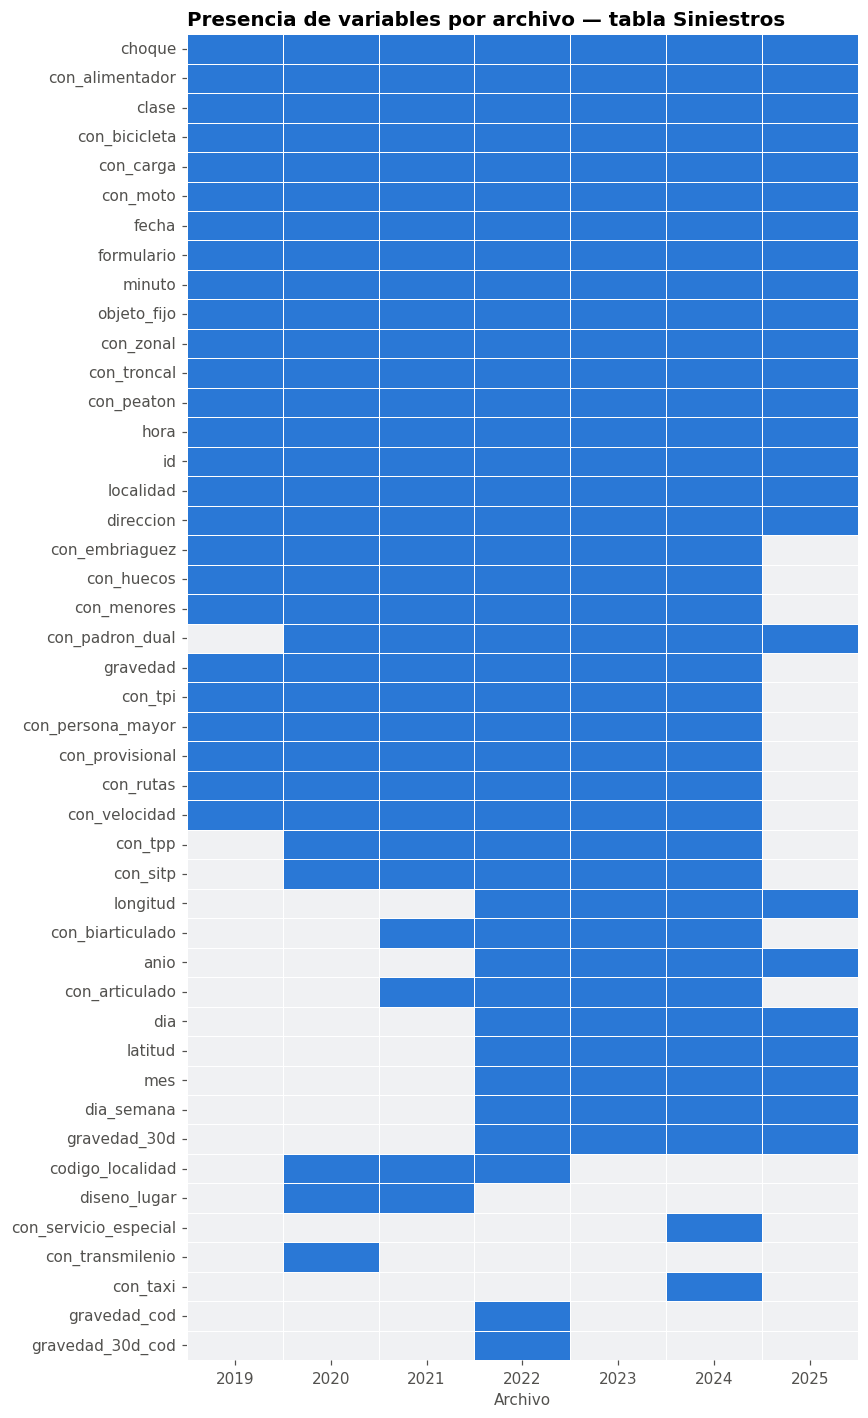

Variables presentes en todos los archivos: ['choque', 'con_alimentador', 'clase', 'con_bicicleta', 'con_carga', 'con_moto', 'fecha', 'formulario', 'minuto', 'objeto_fijo', 'con_zonal', 'con_troncal', 'con_peaton', 'hora', 'id', 'localidad', 'direccion']


In [8]:
def nombre_canonico(c):
    c = unicodedata.normalize('NFKD', str(c)).encode('ascii', 'ignore').decode().lower()
    c = c.replace('siniestro', 'acc').replace('accidente', 'acc')
    alias = {'codigo_acc': 'id', 'fecha': 'fecha', 'fecha_acc': 'fecha', 'fechaacc': 'fecha',
             'gravedadnombre': 'gravedad', 'gravedad_indicador_tradicional': 'gravedad', 'gravedad': 'gravedad_cod',
             'gravedad_indicador_30d': 'gravedad_30d', 'gravedadnombre30': 'gravedad_30d', 'gravedad30': 'gravedad_30d_cod',
             'clasecodigo': 'clase', 'clase': 'clase', 'clase_acc': 'clase', 'clasenombre': 'clase',
             'choquenombre': 'choque', 'choque': 'choque', 'elemento_choque': 'choque',
             'objetofijonombre': 'objeto_fijo', 'objeto_fijo': 'objeto_fijo', 'tipo_objeto_fijo': 'objeto_fijo',
             'hora': 'hora', 'hora_acc': 'hora', 'houracc': 'hora', 'minuto': 'minuto', 'min_acc': 'minuto', 'minuacc': 'minuto',
             'aa_acc': 'anio', 'annoacc': 'anio', 'mm_acc': 'mes', 'mesacc': 'mes', 'dd_mes_acc': 'dia', 'dayacc': 'dia',
             'dia_semana_acc': 'dia_semana', 'wdyacc': 'dia_semana', 'acc': 'id'}
    return alias.get(c, c)

esq = {a: sorted({nombre_canonico(c) for c in t['siniestros'].columns}) for a, t in raw.items()}
todas = sorted(set().union(*esq.values()))
m = pd.DataFrame({a: [int(c in v) for c in todas] for a, v in esq.items()}, index=todas)
m = m.loc[m.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 13))
sns.heatmap(m, cmap=sns.light_palette(AZUL, as_cmap=True), cbar=False, linewidths=.6, linecolor='white', ax=ax)
ax.set_title('Presencia de variables por archivo — tabla Siniestros'); ax.set_xlabel('Archivo'); ax.set_ylabel('')
plt.tight_layout(); plt.show()
print('Variables presentes en todos los archivos:', m.index[m.all(axis=1)].tolist())

### 2.6 ¿Cómo se relacionan los archivos? Conciliación de identificadores

Hipótesis a verificar: el archivo **2024** no es solo del año 2024 sino la serie histórica consolidada. Se compara cada archivo anual 2019–2023 contra él.

In [9]:
h = raw[2024]['siniestros']
print('Años contenidos en el archivo 2024:')
print(h['AA_Acc'].astype(int).value_counts().sort_index().to_string())

ids_hist = set(pd.to_numeric(h['Codigo_Accidente']).astype('int64'))
conc = []
for a in sorted(raw):
    if a == 2024: continue
    s = raw[a]['siniestros']; idc = s.columns[0]
    ids = pd.to_numeric(s[idc], errors='coerce').dropna().astype('int64')
    en_hist = ids.isin(ids_hist)
    n_hist_anio = (h['AA_Acc'].astype(int) == a).sum()
    conc.append({'archivo': a, 'siniestros_archivo': len(s), 'siniestros_mismo_año_en_2024': n_hist_anio,
                 'diferencia': n_hist_anio - len(s), '% ids encontrados en archivo 2024': round(100 * en_hist.mean(), 2)})
pd.DataFrame(conc)

Años contenidos en el archivo 2024:
AA_Acc
2015    31344
2016    34992
2017    35179
2018    37006
2019    34999
2020    22723
2021    28855
2022    25453
2023    14114
2024    13949


,archivo,siniestros_archivo,siniestros_mismo_año_en_2024,diferencia,% ids encontrados en archivo 2024
0,2019,34990,34999,9,100.00
1,2020,22712,22723,11,99.97
2,2021,28841,28855,14,100.00
3,2022,25447,25453,6,100.00
4,2023,14106,14114,8,100.00
5,2025,11573,0,-11573,0.03


## 3. Unificación en un esquema único

In [10]:
def sin_tilde(x):
    if pd.isna(x): return x
    return unicodedata.normalize('NFKD', str(x)).encode('ascii', 'ignore').decode().upper().strip()

MESES = {m: i for i, m in enumerate(['ENERO', 'FEBRERO', 'MARZO', 'ABRIL', 'MAYO', 'JUNIO', 'JULIO', 'AGOSTO',
                                      'SEPTIEMBRE', 'OCTUBRE', 'NOVIEMBRE', 'DICIEMBRE'], 1)}
DIAS = ['LUNES', 'MARTES', 'MIERCOLES', 'JUEVES', 'VIERNES', 'SABADO', 'DOMINGO']

REN_2025 = {  # 2025 -> nombres del archivo 2024
    'Codigo_Siniestro': 'Codigo_Accidente', 'Fecha_Siniestro': 'Fecha_Acc', 'AA_Siniestro': 'AA_Acc',
    'MM_Siniestro': 'MM_Acc', 'DD_Mes_Siniestro': 'DD_Mes_Acc', 'Dia_Semana_Siniestro': 'Dia_Semana_Acc',
    'Hora_Siniestro': 'Hora_Acc', 'Min_Siniestro': 'Min_Acc', 'Clase_Siniestro': 'Clase_Acc',
    'FechaSiniestro': 'FechaAcc', 'AnnoSiniestro': 'AnnoAcc', 'mesSiniestro': 'mesAcc',
    'hourSiniestro': 'hourAcc', 'minuSiniestro': 'minuAcc'}

def a_num(s):
    return pd.to_numeric(s.astype('string').str.replace(',', '.', regex=False), errors='coerce')

def banderas(df):
    out = {}
    for c in df.columns:
        if c.lower().startswith('con_'):
            out[c.lower()] = df[c].astype('string').str.upper().str.strip().isin(['SI', 'S']).astype('boolean')
    return pd.DataFrame(out, index=df.index)

def unificar_siniestros(df, fuente):
    df = df.rename(columns=REN_2025)
    out = pd.DataFrame({
        'id_siniestro': a_num(df['Codigo_Accidente']).astype('Int64'),
        'formulario': df['Formulario'].astype('string'),
        'fecha': pd.to_datetime(df['Fecha_Acc'], errors='coerce').dt.normalize(),
        'hora': a_num(df['Hora_Acc']).astype('Int64'),
        'minuto': a_num(df['Min_Acc']).astype('Int64'),
        'localidad': df['Localidad'].map(sin_tilde).astype('string'),
        'clase': df['Clase_Acc'].map(sin_tilde).astype('string'),
        'elemento_choque': df['Elemento_Choque'].map(sin_tilde).replace('', pd.NA).astype('string'),
        'objeto_fijo': df['Tipo_Objeto_Fijo'].map(sin_tilde).replace('', pd.NA).astype('string'),
        'gravedad': df['Gravedad_indicador_30d'].map(sin_tilde).astype('string'),
        'gravedad_tradicional': (df['Gravedad_Indicador_Tradicional'].map(sin_tilde) if 'Gravedad_Indicador_Tradicional' in df else pd.NA),
        'latitud': a_num(df['Latitud']), 'longitud': a_num(df['Longitud']),
        'direccion': df['Direccion'].astype('string'),
    })
    out['gravedad_tradicional'] = out['gravedad_tradicional'].astype('string')
    out['anio'] = out['fecha'].dt.year.astype('Int64')
    out['mes'] = out['fecha'].dt.month.astype('Int64')
    out['dia_semana'] = pd.Categorical(out['fecha'].dt.dayofweek.map(dict(enumerate(DIAS))), categories=DIAS, ordered=True)
    out = pd.concat([out, banderas(df)], axis=1)
    out['fuente'] = fuente
    return out

def unificar_vehiculos(df, fuente):
    df = df.rename(columns=REN_2025)
    return pd.DataFrame({
        'id_siniestro': a_num(df['Codigo_Accidente']).astype('Int64'),
        'id_vehiculo': a_num(df['Codigo_Vehiculo']).astype('Int64'),
        'anio': a_num(df['AA_Acc']).astype('Int64'),
        'clase_vehiculo': df['Clase'].map(sin_tilde).astype('string'),
        'servicio': df['Servicio'].map(sin_tilde).astype('string'),
        'modalidad': df['Modalidad'].map(sin_tilde).astype('string'),
        'tipo_vehiculo': df['Vehiculo_Viajaba_Clasificado'].map(sin_tilde).astype('string'),
        'tipo_sitp': df['Tipo_SITP'].map(sin_tilde).astype('string'),
        'fuente': fuente})

def unificar_actores(df, fuente):
    df = df.rename(columns=REN_2025)
    sexo = df['Sexo'].map(sin_tilde).replace({'SIN INFORMACION': pd.NA})
    return pd.DataFrame({
        'id_actor': a_num(df['Codigo_Accidentado']).astype('Int64'),
        'id_siniestro': a_num(df['Codigo_Accidente']).astype('Int64'),
        'id_vehiculo': a_num(df['Codigo_Vehiculo']).astype('Int64'),
        'anio': a_num(df['AnnoAcc']).astype('Int64'),
        'edad': a_num(df['Edad']),
        'sexo': sexo.astype('string'),
        'gravedad': df['Gravedad_Indicador_30d'].map(sin_tilde).astype('string'),
        'muerte_posterior': df['Muerte_Posterior'].map(sin_tilde).astype('string'),
        'condicion': df['Condicion'].map(sin_tilde).replace({'SIN INFORMACION': pd.NA}).astype('string'),
        'condicion_especifica': df['Condicion_Especifica'].map(sin_tilde).astype('string'),
        'fuente': fuente})

partes = {'siniestros': [], 'vehiculos': [], 'actores': []}
for anio_arch in [2024, 2025]:
    fuente = f'anuario_{anio_arch}'
    partes['siniestros'].append(unificar_siniestros(raw[anio_arch]['siniestros'], fuente))
    partes['vehiculos'].append(unificar_vehiculos(raw[anio_arch]['vehiculos'], fuente))
    partes['actores'].append(unificar_actores(raw[anio_arch]['actores'], fuente))
sin = pd.concat(partes['siniestros'], ignore_index=True)
veh = pd.concat(partes['vehiculos'], ignore_index=True)
act = pd.concat(partes['actores'], ignore_index=True)
print('Siniestros:', sin.shape, '| Vehículos:', veh.shape, '| Actores:', act.shape)

Siniestros: (290187, 40) | Vehículos: (543142, 9) | Actores: (636184, 11)


### 3.1 Códigos de siniestro que aparecen en el archivo 2024 y en el 2025

In [11]:
dup = sin[sin.duplicated('id_siniestro', keep=False)].sort_values(['id_siniestro', 'anio'])
display(dup[['id_siniestro', 'formulario', 'fecha', 'anio', 'localidad', 'gravedad', 'fuente']])
print('Actores asociados a esos códigos en cada archivo:')
display(act[act.id_siniestro.isin(dup.id_siniestro)].sort_values(['id_siniestro', 'id_actor', 'anio'])
        [['id_siniestro', 'anio', 'id_actor', 'id_vehiculo', 'edad', 'sexo', 'condicion', 'gravedad', 'fuente']])

,id_siniestro,formulario,fecha,anio,localidad,gravedad,fuente
225729,10614270,A001682424,2024-01-03,2024,ENGATIVA,CON HERIDOS,anuario_2024
282795,10614270,A001682424,2025-01-03,2025,ENGATIVA,CON HERIDOS,anuario_2025
228623,10615866,A001682130,2024-02-13,2024,ENGATIVA,CON HERIDOS,anuario_2024
282993,10615866,A001682130,2025-02-13,2025,ENGATIVA,CON HERIDOS,anuario_2025
229055,10615924,A001683962,2024-02-17,2024,SAN CRISTOBAL,CON HERIDOS,anuario_2024
282617,10615924,A001683962,2025-02-17,2025,SAN CRISTOBAL,CON HERIDOS,anuario_2025


Actores asociados a esos códigos en cada archivo:


,id_siniestro,anio,id_actor,id_vehiculo,edad,sexo,condicion,gravedad,fuente
552377,10614270,2024,12916995,1,23.0,MASCULINO,MOTOCICLISTA,HERIDO,anuario_2024
614274,10614270,2025,12916995,1,24.0,MASCULINO,MOTOCICLISTA,HERIDO,anuario_2025
552378,10614270,2024,12916997,2,67.0,MASCULINO,CICLISTA,HERIDO,anuario_2024
614275,10614270,2025,12916997,2,68.0,MASCULINO,CICLISTA,HERIDO,anuario_2025
545447,10615866,2024,12920712,1,42.0,MASCULINO,CONDUCTOR,ILESO,anuario_2024
616273,10615866,2025,12920712,1,43.0,MASCULINO,CONDUCTOR,ILESO,anuario_2025
567284,10615866,2024,12920713,<NA>,39.0,FEMENINO,PEATON,HERIDO,anuario_2024
616274,10615866,2025,12920713,<NA>,40.0,FEMENINO,PEATON,HERIDO,anuario_2025
546727,10615924,2024,12920844,1,33.0,FEMENINO,CONDUCTOR,HERIDO,anuario_2024
617656,10615924,2025,12920844,1,34.0,FEMENINO,CONDUCTOR,HERIDO,anuario_2025


Tres códigos de siniestro aparecen en ambos archivos, cada uno con fecha de un año distinto (2024 y 2025). **Se conservan los dos registros como siniestros distintos**, porque pertenecen a años diferentes y cada archivo los reporta dentro de su propio periodo; no se elimina nada.

Como el código de siniestro por sí solo deja de ser único, **la llave de la base unificada es `(id_siniestro, anio)`**, y con ella se enlazan vehículos `(id_siniestro, anio, id_vehiculo)` y actores `(id_actor, anio)`. Así ningún registro de un año se mezcla con el del otro.

In [12]:
LLAVE = ['id_siniestro', 'anio']
# Atributos del siniestro que se heredan a actores y vehículos para el análisis (unión por la llave compuesta)
llaves = sin[LLAVE + ['fecha', 'mes', 'hora', 'dia_semana', 'localidad', 'clase', 'gravedad']].rename(columns={'gravedad': 'gravedad_siniestro'})
n_act, n_veh = len(act), len(veh)
act = act.merge(llaves, on=LLAVE, how='left', validate='many_to_one')
veh = veh.merge(llaves, on=LLAVE, how='left', validate='many_to_one')
assert len(act) == n_act and len(veh) == n_veh   # la unión no duplica filas
print('Base unificada:', sin.shape, veh.shape, act.shape)
print('Periodo:', sin.fecha.min().date(), '→', sin.fecha.max().date())
sin.head()

Base unificada: (290187, 40) (543142, 16) (636184, 18)
Periodo: 2015-01-01 → 2025-12-31


,id_siniestro,formulario,fecha,hora,minuto,localidad,clase,elemento_choque,objeto_fijo,gravedad,gravedad_tradicional,latitud,longitud,direccion,anio,mes,dia_semana,con_bicicleta,con_carga,con_embriaguez,con_huecos,con_menores,con_moto,con_peaton,con_persona_mayor,con_rutas,con_tpi,con_tpp,con_velocidad,con_sitp,con_troncal,con_alimentador,con_zonal,con_provisional,con_articulado,con_biarticulado,con_padron_dual,con_servicio_especial,con_taxi,fuente
0,4404210,A685,2015-02-09,20,40,BOSA,CHOQUE,VEHICULO,<NA>,CON MUERTOS,CON MUERTOS,4.621978,-74.181387,AV AVENIDA CIUDAD DE CALI-KR 55 S 02,2015,2,LUNES,True,False,False,False,True,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,anuario_2024
1,4404211,A666,2015-02-06,15,50,USAQUEN,CHOQUE,VEHICULO,<NA>,SOLO DANOS,SOLO DANOS,4.762901,-74.027304,AK 7-CL 186 02,2015,2,VIERNES,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,True,False,False,False,False,False,False,anuario_2024
2,4404212,A698,2015-02-07,12,30,USAQUEN,CHOQUE,VEHICULO,<NA>,SOLO DANOS,SOLO DANOS,4.706939,-74.053529,KR 45-CL 127 02,2015,2,SABADO,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,anuario_2024
3,4404213,A000042495,2015-02-09,13,45,RAFAEL URIBE URIBE,VOLCAMIENTO,<NA>,<NA>,CON MUERTOS,CON MUERTOS,4.576256,-74.099563,KR 12-CL 24 S 06,2015,2,LUNES,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,anuario_2024
4,4404214,A644,2015-02-08,10,58,SAN CRISTOBAL,CHOQUE,VEHICULO,<NA>,SOLO DANOS,SOLO DANOS,4.52408,-74.091667,CL 70-KR 11D SE 04,2015,2,DOMINGO,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,anuario_2024


## 4. Calidad de los datos
### 4.1 Unicidad e integridad referencial

In [13]:
chequeos = {
    'id_siniestro único (solo)': sin['id_siniestro'].is_unique,
    '(id_siniestro, anio) único en siniestros': not sin.duplicated(LLAVE).any(),
    '(formulario, anio) único en siniestros': not sin.duplicated(['formulario', 'anio']).any(),
    '(id_actor, anio) único en actores': not act.duplicated(['id_actor', 'anio']).any(),
    '(id_siniestro, anio, id_vehiculo) único en vehículos': not veh.duplicated(LLAVE + ['id_vehiculo']).any(),
    '% actores cuyo siniestro existe': round(100 * act['fecha'].notna().mean(), 3),
    '% vehículos cuyo siniestro existe': round(100 * veh['fecha'].notna().mean(), 3),
    '% siniestros con al menos un actor': round(100 * sin.set_index(LLAVE).index.isin(act.set_index(LLAVE).index).mean(), 3),
    '% siniestros con al menos un vehículo': round(100 * sin.set_index(LLAVE).index.isin(veh.set_index(LLAVE).index).mean(), 3),
}
pd.Series(chequeos, name='resultado').to_frame()

,resultado
id_siniestro único (solo),False
"(id_siniestro, anio) único en siniestros",True
"(formulario, anio) único en siniestros",True
"(id_actor, anio) único en actores",True
"(id_siniestro, anio, id_vehiculo) único en vehículos",True
% actores cuyo siniestro existe,100.0
% vehículos cuyo siniestro existe,100.0
% siniestros con al menos un actor,99.948
% siniestros con al menos un vehículo,99.949


### 4.2 Valores faltantes
Las banderas `CON_*` se convierten a verdadero/falso (vacío = no). Se muestran las variables descriptivas; nótese que en el archivo 2025 varias banderas **no existen** (no es lo mismo que "no").

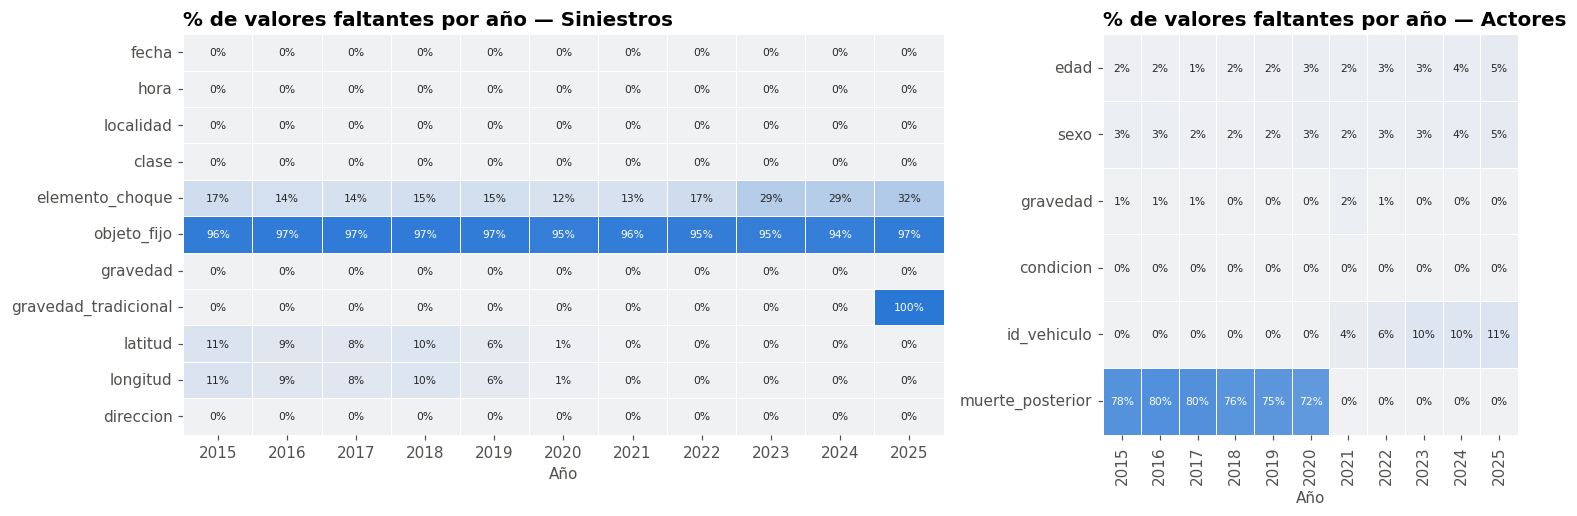

In [14]:
desc_cols = ['fecha', 'hora', 'localidad', 'clase', 'elemento_choque', 'objeto_fijo', 'gravedad', 'gravedad_tradicional', 'latitud', 'longitud', 'direccion']
nul_sin = sin.groupby('anio')[desc_cols].apply(lambda d: d.isna().mean()).T
nul_act = act.groupby('anio')[['edad', 'sexo', 'gravedad', 'condicion', 'id_vehiculo', 'muerte_posterior']].apply(lambda d: d.isna().mean()).T
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [11, 6]})
for ax, d, t in [(axes[0], nul_sin, 'Siniestros'), (axes[1], nul_act, 'Actores')]:
    sns.heatmap(d, annot=True, fmt='.0%', cmap=sns.light_palette(AZUL, as_cmap=True), vmin=0, vmax=1, cbar=False,
                linewidths=.6, linecolor='white', ax=ax, annot_kws={'size': 7})
    ax.set_title(f'% de valores faltantes por año — {t}'); ax.set_xlabel('Año'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

In [15]:
flag_cols = [c for c in sin.columns if c.startswith('con_')]
presentes_2025 = [c for c in flag_cols if c.lower() in [x.lower() for x in raw[2025]['siniestros'].columns]]
print('Banderas en 2015–2024:', len(flag_cols), '| presentes en 2025:', len(presentes_2025))
print('Ausentes en 2025:', sorted(set(flag_cols) - set(presentes_2025)))

Banderas en 2015–2024: 22 | presentes en 2025: 8
Ausentes en 2025: ['con_articulado', 'con_biarticulado', 'con_embriaguez', 'con_huecos', 'con_menores', 'con_persona_mayor', 'con_provisional', 'con_rutas', 'con_servicio_especial', 'con_sitp', 'con_taxi', 'con_tpi', 'con_tpp', 'con_velocidad']


### 4.3 Rangos y valores atípicos

In [16]:
LAT, LON = (3.7, 4.9), (-74.5, -73.95)   # caja amplia que contiene el Distrito (incluye Sumapaz)
fuera = ~(sin.latitud.between(*LAT) & sin.longitud.between(*LON)) & sin.latitud.notna()
print(f'Siniestros sin coordenadas: {sin.latitud.isna().sum():,} ({sin.latitud.isna().mean():.1%})')
print(f'Coordenadas fuera de Bogotá: {fuera.sum():,}')
print(f'Edades > 100 años: {(act.edad > 100).sum():,}  (ej.: {sorted(act.edad[act.edad > 100].unique())[:8]})')
print(f'Edades = 0: {(act.edad == 0).sum():,}')
print(f'Horas fuera de 0–23: {(~sin.hora.between(0, 23)).sum():,}')
act.loc[act.edad > 100, 'edad'] = np.nan     # se tratan como faltantes
sin.loc[fuera, ['latitud', 'longitud']] = np.nan
act['edad'].describe().round(1).to_frame().T

Siniestros sin coordenadas: 15,065 (5.2%)
Coordenadas fuera de Bogotá: 0
Edades > 100 años: 386  (ej.: [np.float64(101.0), np.float64(102.0), np.float64(103.0), np.float64(104.0), np.float64(105.0), np.float64(106.0), np.float64(107.0), np.float64(109.0)])
Edades = 0: 573
Horas fuera de 0–23: 0


,count,mean,std,min,25%,50%,75%,max
edad,620951.0,37.5,14.3,0.0,26.0,35.0,47.0,100.0


### 4.4 Guardar la base unificada (para DVC)

In [17]:
for nombre, df in [('siniestros', sin), ('vehiculos', veh), ('actores', act)]:
    d = df.copy()
    if 'dia_semana' in d: d['dia_semana'] = d['dia_semana'].astype('string')
    d.to_parquet(PROC_DIR / f'{nombre}_2015_2025.parquet', index=False)
    print(f'{nombre:<11} {len(d):>8,} filas → {PROC_DIR / f"{nombre}_2015_2025.parquet"}')

siniestros   290,187 filas → data/processed/siniestros_2015_2025.parquet
vehiculos    543,142 filas → data/processed/vehiculos_2015_2025.parquet
actores      636,184 filas → data/processed/actores_2015_2025.parquet


### 4.5 Ficha descriptiva de la base unificada

In [18]:
def ficha(df, nombre):
    r = []
    for c in df.columns:
        s = df[c]
        r.append({'tabla': nombre, 'variable': c, 'tipo': str(s.dtype), '% nulos': round(100 * s.isna().mean(), 1),
                  'n_únicos': s.nunique(dropna=True),
                  'ejemplo / rango': (f'{s.min()} – {s.max()}' if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
                                      else ', '.join(map(str, s.dropna().astype(str).value_counts().index[:3])))})
    return pd.DataFrame(r)
fichas = pd.concat([ficha(sin.drop(columns=flag_cols), 'siniestros'), ficha(veh, 'vehiculos'), ficha(act, 'actores')])
with pd.option_context('display.max_rows', 100): display(fichas)

,tabla,variable,tipo,% nulos,n_únicos,ejemplo / rango
0,siniestros,id_siniestro,Int64,0.0,290184,4401419 – 11342496
1,siniestros,formulario,string,0.0,290184,"A001682424, A001682130, A001683962"
2,siniestros,fecha,datetime64[ns],0.0,4018,"2019-12-06, 2018-05-11, 2021-12-07"
3,siniestros,hora,Int64,0.0,24,0 – 23
4,siniestros,minuto,Int64,0.0,60,0 – 59
5,siniestros,localidad,string,0.0,20,"KENNEDY, ENGATIVA, USAQUEN"
6,siniestros,clase,string,0.0,7,"CHOQUE, ATROPELLO, CAIDA DE OCUPANTE"
7,siniestros,elemento_choque,string,16.7,4,"VEHICULO, OBJETO FIJO, SEMOVIENTE"
8,siniestros,objeto_fijo,string,96.3,17,"SEMAFORO, TREN, VEHICULO"
9,siniestros,gravedad,string,0.1,3,"SOLO DANOS, CON HERIDOS, CON MUERTOS"


## 5. Exploración de datos — nivel siniestro
### 5.1 Siniestros por año y gravedad: un quiebre de registro

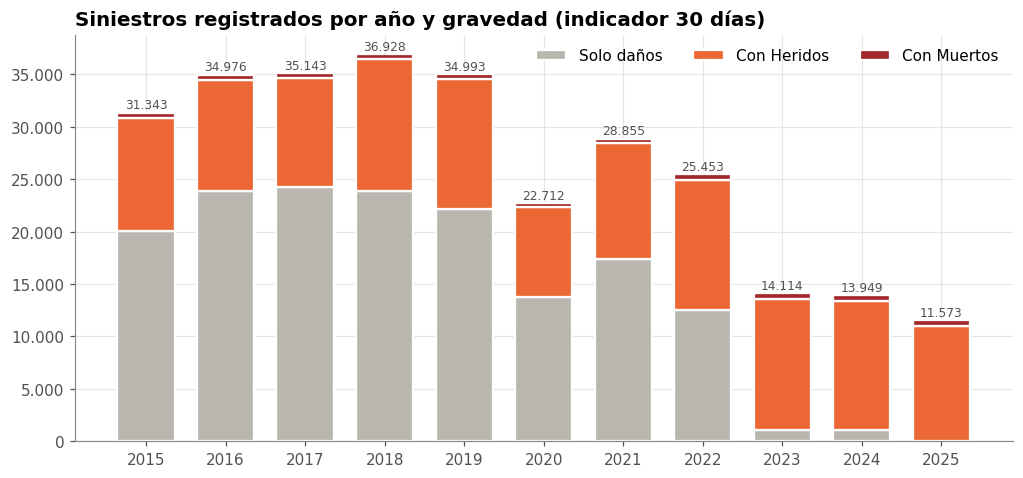

gravedad,SOLO DANOS,CON HERIDOS,CON MUERTOS,total
anio,,,,
2015,20088,10738,517,31343
2016,23852,10581,543,34976
2017,24217,10403,523,35143
2018,23857,12586,485,36928
2019,22122,12402,469,34993
2020,13776,8580,356,22712
2021,17388,11015,452,28855
2022,12566,12371,516,25453
2023,1115,12473,526,14114


In [19]:
ORD = ['SOLO DANOS', 'CON HERIDOS', 'CON MUERTOS']
anual = sin.pivot_table(index='anio', columns='gravedad', values='id_siniestro', aggfunc='count').reindex(columns=ORD).fillna(0)
fig, ax = plt.subplots()
abajo = np.zeros(len(anual))
for g in ORD:
    ax.bar(anual.index, anual[g], bottom=abajo, color=GRAV_COL[g], label=g.title().replace('Danos', 'daños'), width=.72, edgecolor='white', linewidth=1.5)
    abajo += anual[g].values
for x, t in zip(anual.index, anual.sum(axis=1)): ax.text(x, t + 400, f'{t:,.0f}'.replace(',', '.'), ha='center', fontsize=8, color='#52514e')
ax.yaxis.set_major_formatter(miles); ax.set_xticks(anual.index)
ax.set_title('Siniestros registrados por año y gravedad (indicador 30 días)'); ax.legend(loc='upper right', ncol=3)
plt.show()
anual.astype(int).assign(total=lambda d: d.sum(axis=1))

Los siniestros **solo daños** caen bruscamente desde 2022–2023 y desaparecen en 2025, mientras los siniestros con heridos y con muertos se mantienen estables. Es un cambio en el registro (qué siniestros quedan en la base), no una mejora real de la seguridad vial. **Consecuencia para el proyecto:** las comparaciones en el tiempo deben hacerse sobre **siniestros con víctimas (heridos o muertos)**, que tienen registro consistente en todo el periodo. Ese es el universo de análisis del resto del notebook salvo que se indique otra cosa.

In [20]:
cv = sin[sin.gravedad.isin(['CON HERIDOS', 'CON MUERTOS'])].copy()
cv['fatal'] = (cv.gravedad == 'CON MUERTOS')
print(f'Universo de análisis: {len(cv):,} siniestros con víctimas ({cv.anio.min()}–{cv.anio.max()})')

Universo de análisis: 130,021 siniestros con víctimas (2015–2025)


### 5.2 Tendencia mensual de siniestros con víctimas

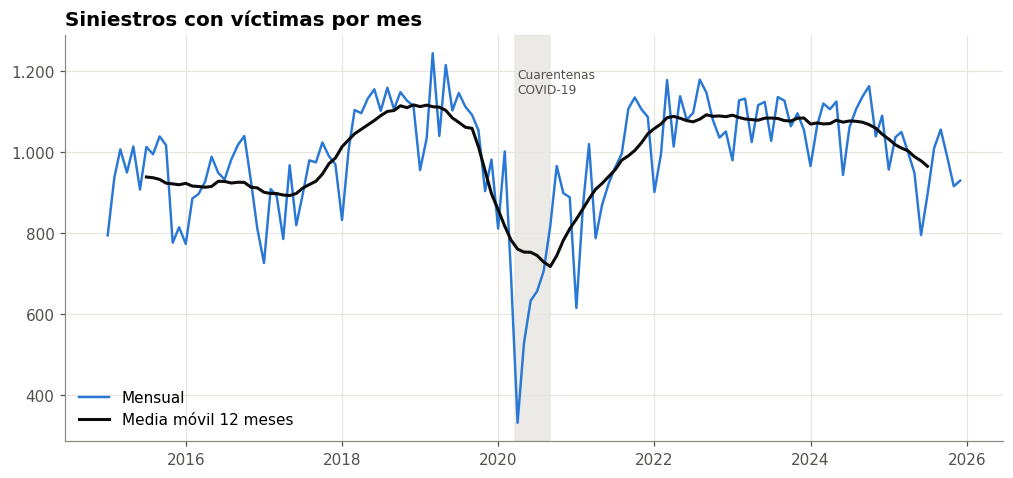

Mes mínimo: 2020-04 332 | Mes máximo: 2019-03 1243


In [21]:
mens = cv.set_index('fecha').resample('MS')['id_siniestro'].count()
fig, ax = plt.subplots()
ax.plot(mens.index, mens.values, color=AZUL, lw=1.6, label='Mensual')
ax.plot(mens.index, mens.rolling(12, center=True).mean(), color='#0b0b0b', lw=2, label='Media móvil 12 meses')
ax.axvspan(pd.Timestamp('2020-03-20'), pd.Timestamp('2020-08-31'), color='#e6e5e0', alpha=.8, zorder=0)
ax.text(pd.Timestamp('2020-04-01'), mens.max() * .97, 'Cuarentenas\nCOVID-19', fontsize=8, color='#52514e', va='top')
ax.yaxis.set_major_formatter(miles); ax.set_title('Siniestros con víctimas por mes'); ax.legend(loc='lower left')
plt.show()
print('Mes mínimo:', mens.idxmin().strftime('%Y-%m'), int(mens.min()), '| Mes máximo:', mens.idxmax().strftime('%Y-%m'), int(mens.max()))

### 5.3 ¿Cuándo ocurren? Día de la semana × hora

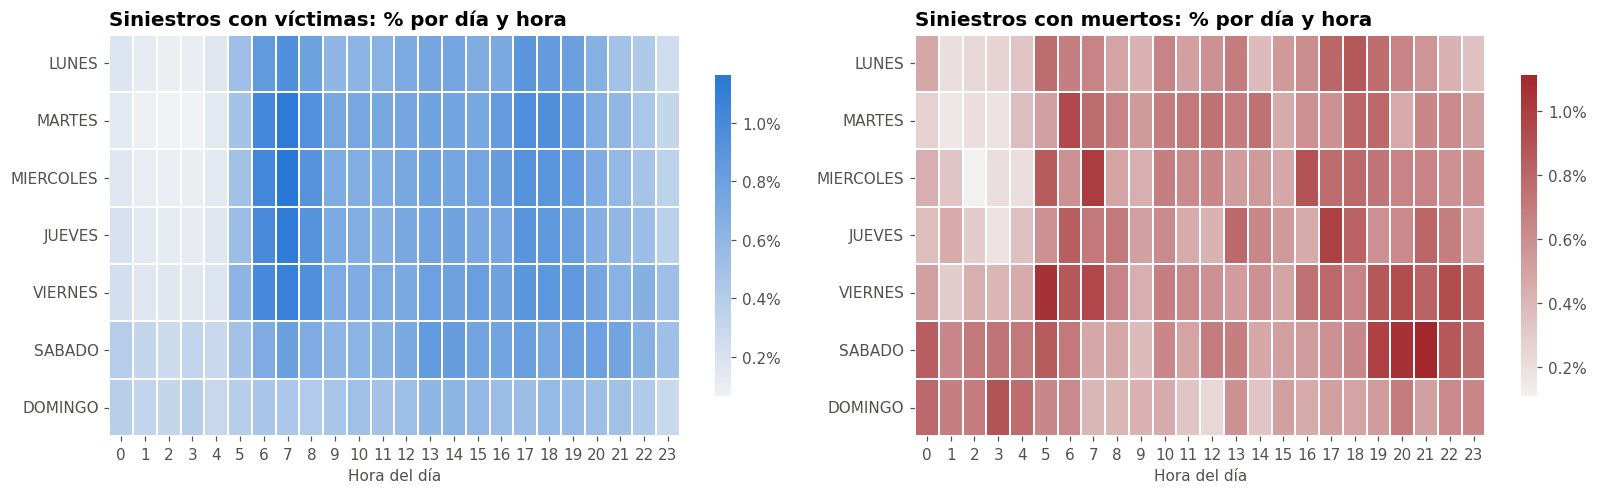

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, d, t in [(axes[0], cv, 'Siniestros con víctimas'), (axes[1], cv[cv.fatal], 'Siniestros con muertos')]:
    tab = d.pivot_table(index='dia_semana', columns='hora', values='id_siniestro', aggfunc='count', observed=False).fillna(0).astype(float)
    sns.heatmap(tab / tab.values.sum(), cmap=sns.light_palette(AZUL if 'víct' in t else '#a3282b', as_cmap=True),
                cbar_kws={'format': mtick.PercentFormatter(1, 1), 'shrink': .8}, linewidths=.3, linecolor='white', ax=ax)
    ax.set_title(f'{t}: % por día y hora'); ax.set_xlabel('Hora del día'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

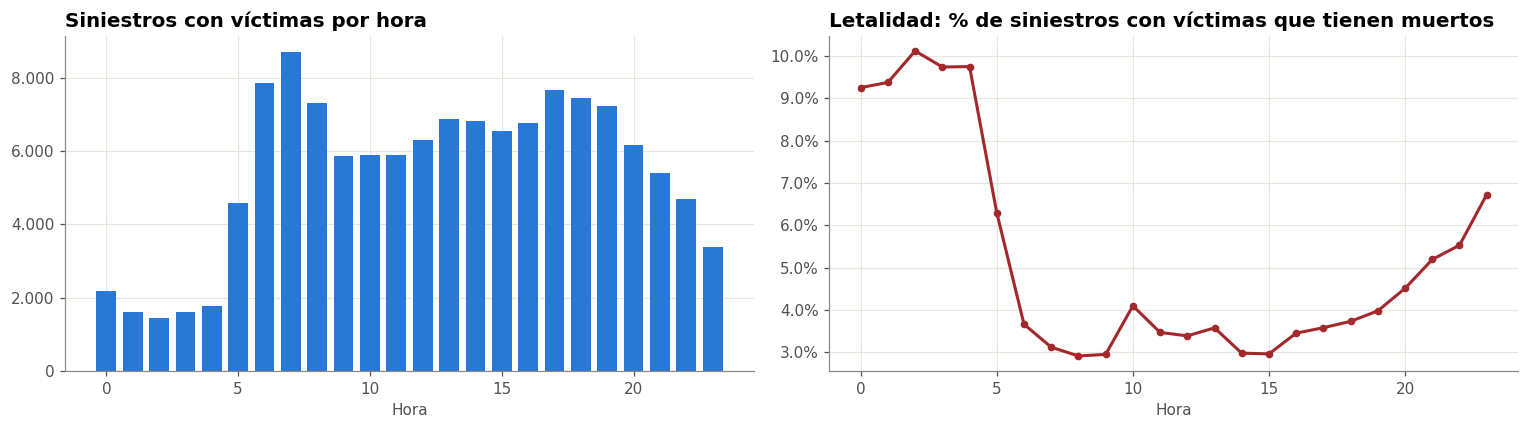

Hora con más siniestros: 7 | hora con mayor letalidad: 2 (10.1%) | letalidad promedio: 4.22%


In [23]:
hora = cv.groupby('hora').agg(siniestros=('id_siniestro', 'count'), letalidad=('fatal', 'mean'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(hora.index, hora.siniestros, color=AZUL, width=.75); axes[0].yaxis.set_major_formatter(miles)
axes[0].set_title('Siniestros con víctimas por hora'); axes[0].set_xlabel('Hora')
axes[1].plot(hora.index, hora.letalidad, color='#a3282b', lw=2, marker='o', ms=4); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, 1))
axes[1].set_title('Letalidad: % de siniestros con víctimas que tienen muertos'); axes[1].set_xlabel('Hora')
plt.tight_layout(); plt.show()
print('Hora con más siniestros:', hora.siniestros.idxmax(), '| hora con mayor letalidad:', hora.letalidad.idxmax(), f'({hora.letalidad.max():.1%})',
      '| letalidad promedio:', f'{cv.fatal.mean():.2%}')

In [24]:
dia = cv.groupby('dia_semana', observed=False).agg(siniestros=('id_siniestro', 'count'), con_muertos=('fatal', 'sum'), letalidad=('fatal', 'mean'))
dia.style.format({'siniestros': '{:,.0f}', 'con_muertos': '{:,.0f}', 'letalidad': '{:.2%}'})

,siniestros,con_muertos,letalidad
dia_semana,,,
LUNES,"17,633",708,4.02%
MARTES,"19,388",748,3.86%
MIERCOLES,"19,277",756,3.92%
JUEVES,"19,227",762,3.96%
VIERNES,"20,421",884,4.33%
SABADO,"19,678",908,4.61%
DOMINGO,"14,397",723,5.02%


### 5.4 ¿Dónde ocurren? Localidades

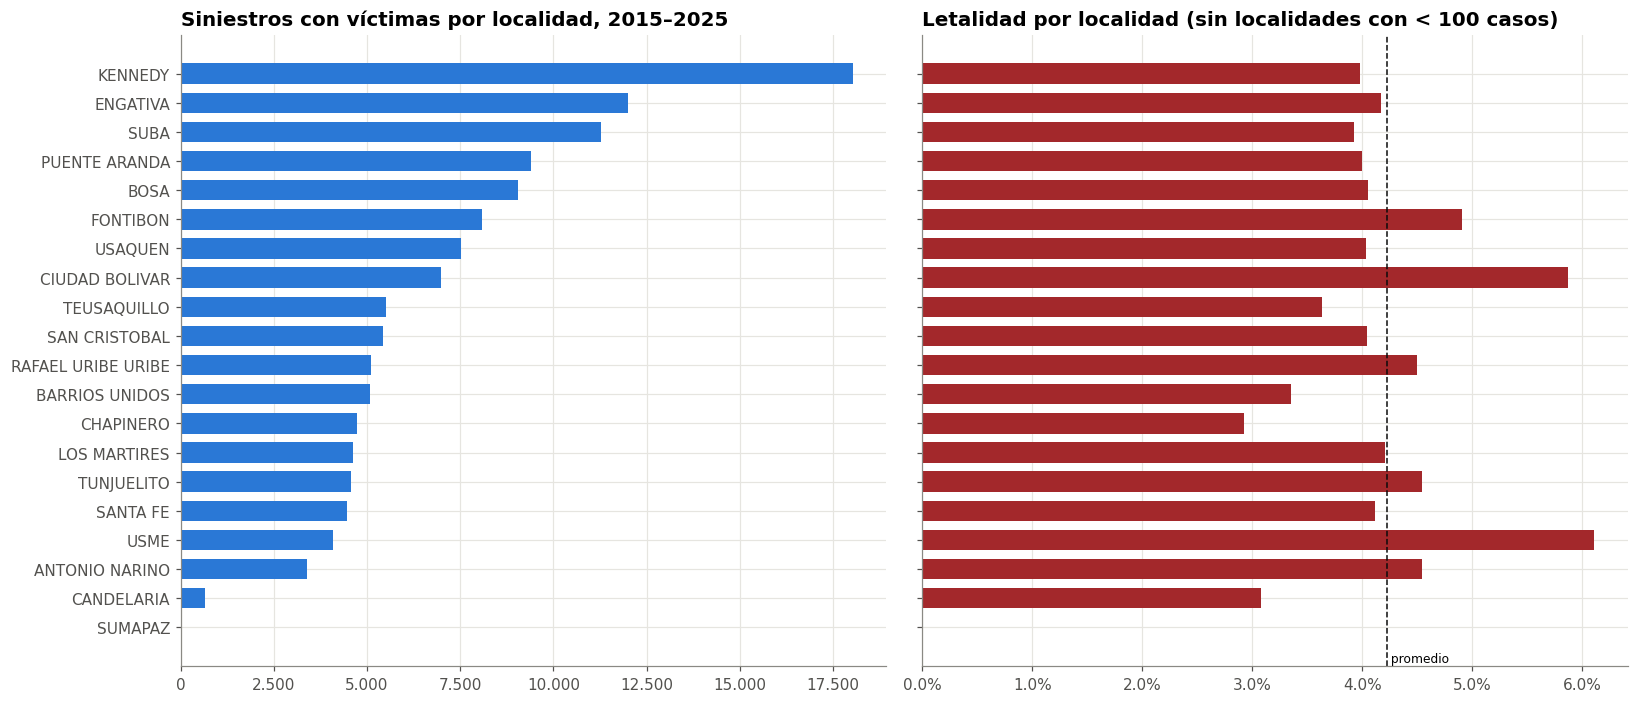

,siniestros,con_muertos,letalidad,% del total
localidad,,,,
KENNEDY,"18,033",718,3.98%,13.9%
ENGATIVA,"12,006",501,4.17%,9.2%
SUBA,"11,269",442,3.92%,8.7%
PUENTE ARANDA,"9,405",376,4.00%,7.2%
BOSA,"9,054",367,4.05%,7.0%
FONTIBON,"8,076",396,4.90%,6.2%
USAQUEN,"7,532",304,4.04%,5.8%
CIUDAD BOLIVAR,"6,983",410,5.87%,5.4%
TEUSAQUILLO,"5,501",200,3.64%,4.2%


In [25]:
loc = (cv[cv.localidad.notna()].groupby('localidad')
         .agg(siniestros=('id_siniestro', 'count'), con_muertos=('fatal', 'sum'), letalidad=('fatal', 'mean'))
         .sort_values('siniestros'))
loc['% del total'] = loc.siniestros / loc.siniestros.sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
axes[0].barh(loc.index, loc.siniestros, color=AZUL, height=.7); axes[0].xaxis.set_major_formatter(miles)
axes[0].set_title('Siniestros con víctimas por localidad, 2015–2025')
let_plot = loc.letalidad.where(loc.siniestros >= 100, 0).astype(float)   # localidades con <100 casos (Sumapaz) no se grafican: tasa inestable
axes[1].barh(loc.index, let_plot, color='#a3282b', height=.7); axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1, 1))
axes[1].axvline(cv.fatal.mean(), color='#0b0b0b', lw=1, ls='--'); axes[1].text(cv.fatal.mean(), -1.2, ' promedio', fontsize=8)
axes[1].set_title('Letalidad por localidad (sin localidades con < 100 casos)')
plt.tight_layout(); plt.show()
loc.sort_values('siniestros', ascending=False).style.format({'siniestros': '{:,.0f}', 'con_muertos': '{:,.0f}', 'letalidad': '{:.2%}', '% del total': '{:.1%}'})

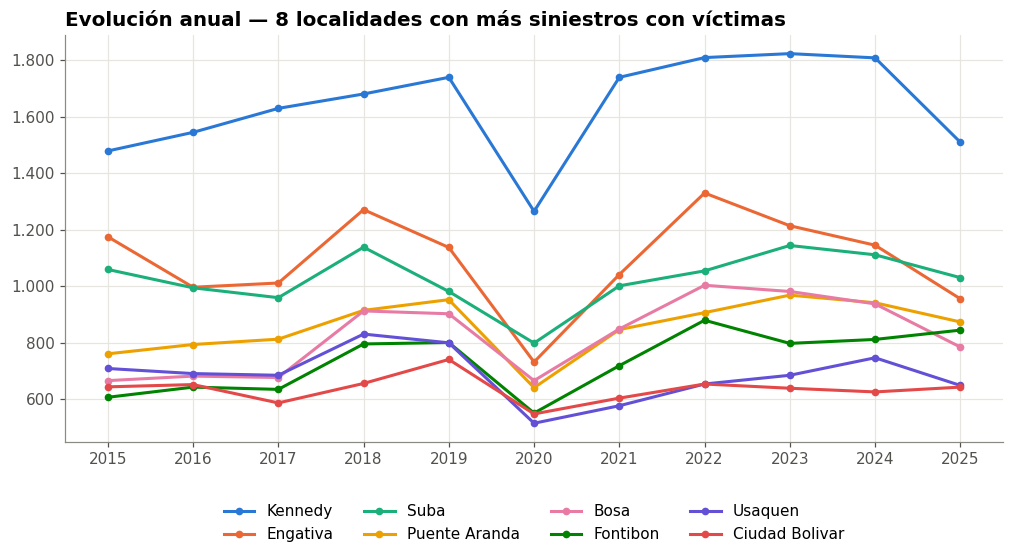

In [26]:
top = loc.sort_values('siniestros', ascending=False).index[:8]
ev = cv[cv.localidad.isin(top)].pivot_table(index='anio', columns='localidad', values='id_siniestro', aggfunc='count')[top]
fig, ax = plt.subplots()
for i, c in enumerate(top): ax.plot(ev.index, ev[c], color=CAT[i], lw=2, marker='o', ms=4, label=c.title())
ax.yaxis.set_major_formatter(miles); ax.set_xticks(ev.index); ax.set_title('Evolución anual — 8 localidades con más siniestros con víctimas')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, -.12)); plt.show()

### 5.5 Mapa de puntos (coordenadas)

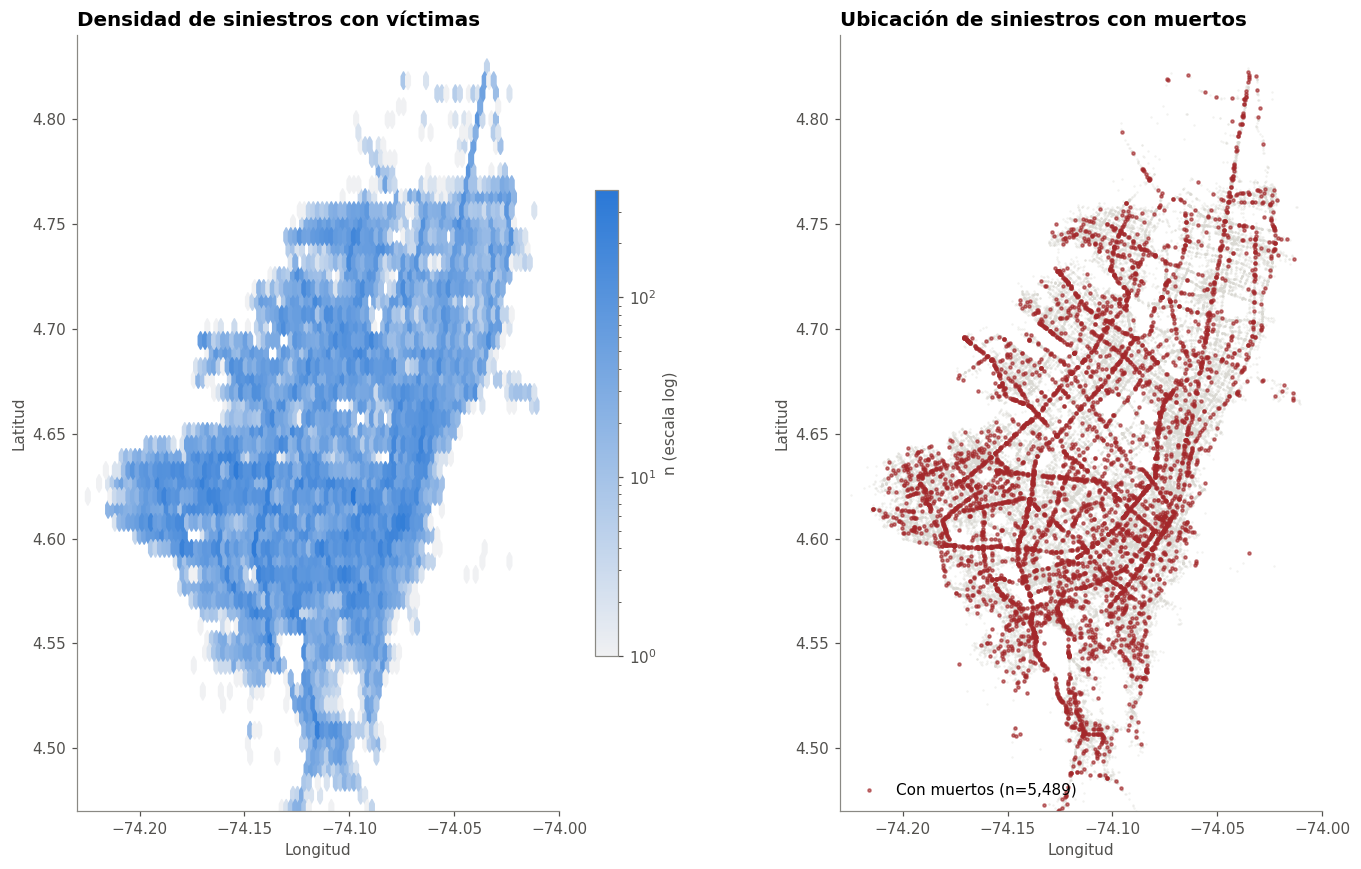

Siniestros con víctimas con coordenadas válidas: 125,449 de 130,021 (96.5%)


In [27]:
geo = cv.dropna(subset=['latitud', 'longitud'])
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
hb = axes[0].hexbin(geo.longitud, geo.latitud, gridsize=110, bins='log', cmap=sns.light_palette(AZUL, as_cmap=True), mincnt=1)
axes[0].set_title('Densidad de siniestros con víctimas'); fig.colorbar(hb, ax=axes[0], shrink=.6, label='n (escala log)')
g2 = geo[geo.fatal]
axes[1].scatter(geo.longitud, geo.latitud, s=.2, color='#d9d8d2', alpha=.4, rasterized=True)
axes[1].scatter(g2.longitud, g2.latitud, s=4, color='#a3282b', alpha=.6, label=f'Con muertos (n={len(g2):,})')
axes[1].set_title('Ubicación de siniestros con muertos'); axes[1].legend(loc='lower left')
for ax in axes: ax.set_xlim(-74.23, -74.0); ax.set_ylim(4.47, 4.84); ax.set_aspect('equal'); ax.grid(False); ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
plt.tight_layout(); plt.show()
print(f'Siniestros con víctimas con coordenadas válidas: {len(geo):,} de {len(cv):,} ({len(geo)/len(cv):.1%})')

### 5.6 Tipo de siniestro

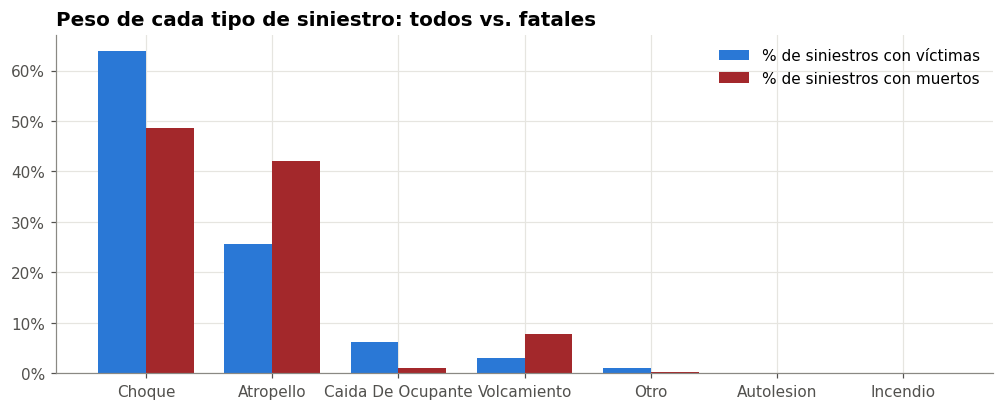

,siniestros,con_muertos,letalidad,% siniestros,% de los fatales
clase,,,,,
CHOQUE,"83,131","2,668",3.21%,63.9%,48.6%
ATROPELLO,"33,351","2,314",6.94%,25.7%,42.2%
CAIDA DE OCUPANTE,"8,153",61,0.75%,6.3%,1.1%
VOLCAMIENTO,"4,057",429,10.57%,3.1%,7.8%
OTRO,"1,310",17,1.30%,1.0%,0.3%
AUTOLESION,14,0,0.00%,0.0%,0.0%
INCENDIO,5,0,0.00%,0.0%,0.0%


In [29]:
cl = cv.groupby('clase').agg(siniestros=('id_siniestro', 'count'), con_muertos=('fatal', 'sum'), letalidad=('fatal', 'mean')).sort_values('siniestros', ascending=False)
cl['% siniestros'] = cl.siniestros / cl.siniestros.sum(); cl['% de los fatales'] = cl.con_muertos / cl.con_muertos.sum()
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(cl)); w = .38
ax.bar(x - w/2, cl['% siniestros'], w, color=AZUL, label='% de siniestros con víctimas')
ax.bar(x + w/2, cl['% de los fatales'], w, color='#a3282b', label='% de siniestros con muertos')
ax.set_xticks(x, [c.title() for c in cl.index]); ax.yaxis.set_major_formatter(pct); ax.legend()
ax.set_title('Peso de cada tipo de siniestro: todos vs. fatales'); plt.show()
cl.style.format({'siniestros': '{:,.0f}', 'con_muertos': '{:,.0f}', 'letalidad': '{:.2%}', '% siniestros': '{:.1%}', '% de los fatales': '{:.1%}'})

### 5.7 Factores asociados (banderas `CON_*`)
Para cada bandera: qué tan frecuente es en los siniestros con víctimas y cuánto cambia la letalidad cuando está presente (**riesgo relativo** = letalidad con la bandera / letalidad sin ella). Solo 2015–2024, porque 2025 no trae todas las banderas.

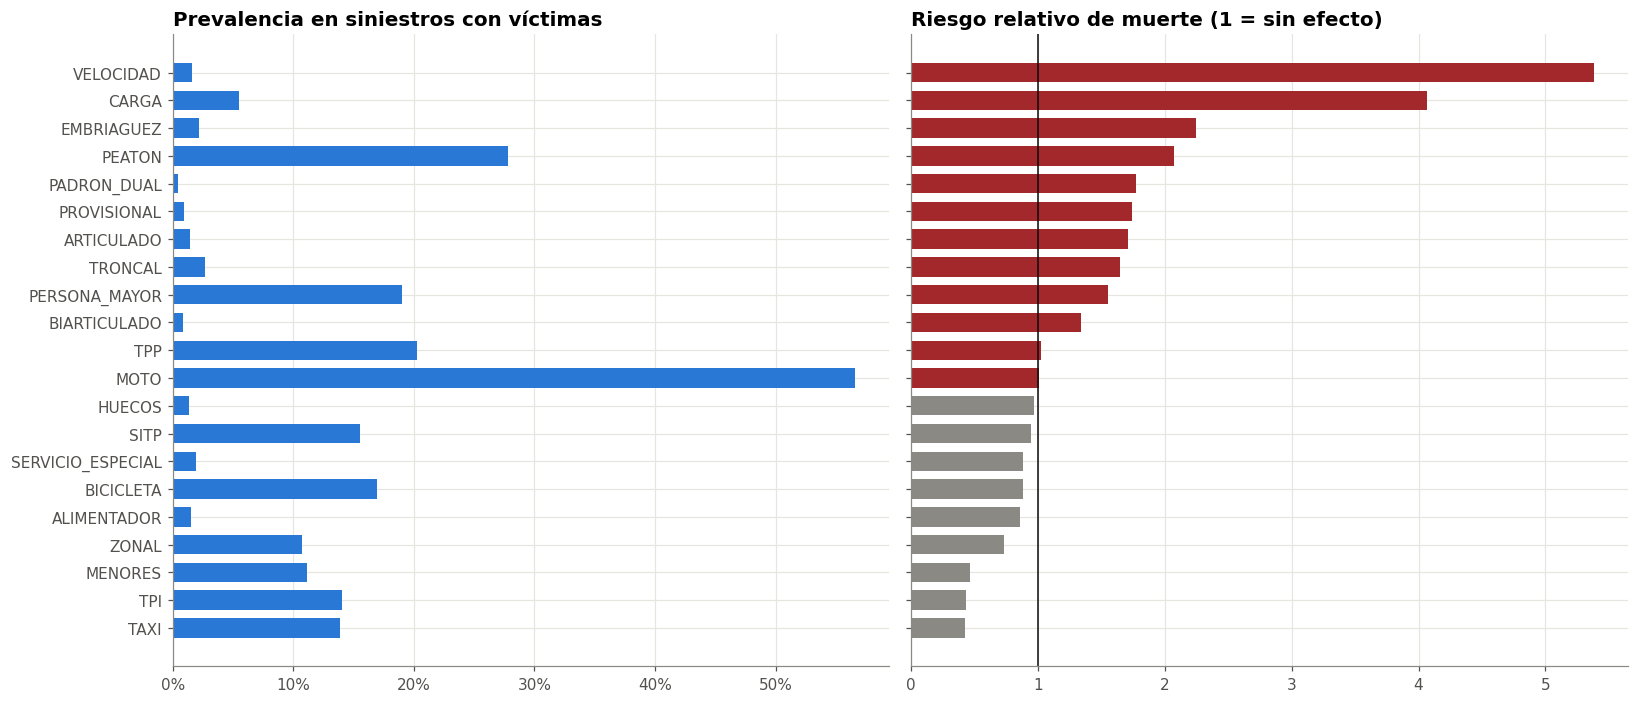

factor,prevalencia,siniestros,letalidad_con,letalidad_sin,riesgo_relativo
VELOCIDAD,1.6%,"1,939",20.94%,3.89%,5.38
CARGA,5.5%,"6,556",14.51%,3.56%,4.07
EMBRIAGUEZ,2.2%,"2,556",9.12%,4.06%,2.25
PEATON,27.8%,"32,892",6.65%,3.21%,2.07
PADRON_DUAL,0.4%,515,7.38%,4.15%,1.78
PROVISIONAL,0.9%,"1,080",7.22%,4.14%,1.74
ARTICULADO,1.4%,"1,657",7.06%,4.13%,1.71
TRONCAL,2.6%,"3,134",6.73%,4.10%,1.64
PERSONA_MAYOR,19.0%,"22,522",5.84%,3.78%,1.55
BIARTICULADO,0.9%,"1,008",5.56%,4.16%,1.34


In [30]:
base = cv[cv.anio <= 2024]
rr = []
for c in flag_cols:
    m = base[c].fillna(False).astype(bool)
    if m.sum() < 200: continue
    rr.append({'factor': c.replace('con_', '').upper(), 'prevalencia': m.mean(), 'siniestros': int(m.sum()),
               'letalidad_con': base.fatal[m].mean(), 'letalidad_sin': base.fatal[~m].mean()})
rr = pd.DataFrame(rr); rr['riesgo_relativo'] = rr.letalidad_con / rr.letalidad_sin
rr = rr.sort_values('riesgo_relativo')
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
axes[0].barh(rr.factor, rr.prevalencia, color=AZUL, height=.7); axes[0].xaxis.set_major_formatter(pct)
axes[0].set_title('Prevalencia en siniestros con víctimas')
col = ['#a3282b' if v > 1 else '#8a8984' for v in rr.riesgo_relativo]
axes[1].barh(rr.factor, rr.riesgo_relativo, color=col, height=.7); axes[1].axvline(1, color='#0b0b0b', lw=1)
axes[1].set_title('Riesgo relativo de muerte (1 = sin efecto)')
plt.tight_layout(); plt.show()
rr.sort_values('riesgo_relativo', ascending=False).style.hide(axis='index').format({'prevalencia': '{:.1%}', 'siniestros': '{:,.0f}', 'letalidad_con': '{:.2%}', 'letalidad_sin': '{:.2%}', 'riesgo_relativo': '{:.2f}'})

> Los riesgos relativos son asociaciones descriptivas, no efectos causales: una bandera puede coincidir con otras (p. ej. peatón y persona mayor). Sirven para priorizar variables para el modelo y para el prototipo.

## 6. Exploración de datos — nivel persona (actor vial) y vehículo
### 6.1 Víctimas por año: heridos y fallecidos

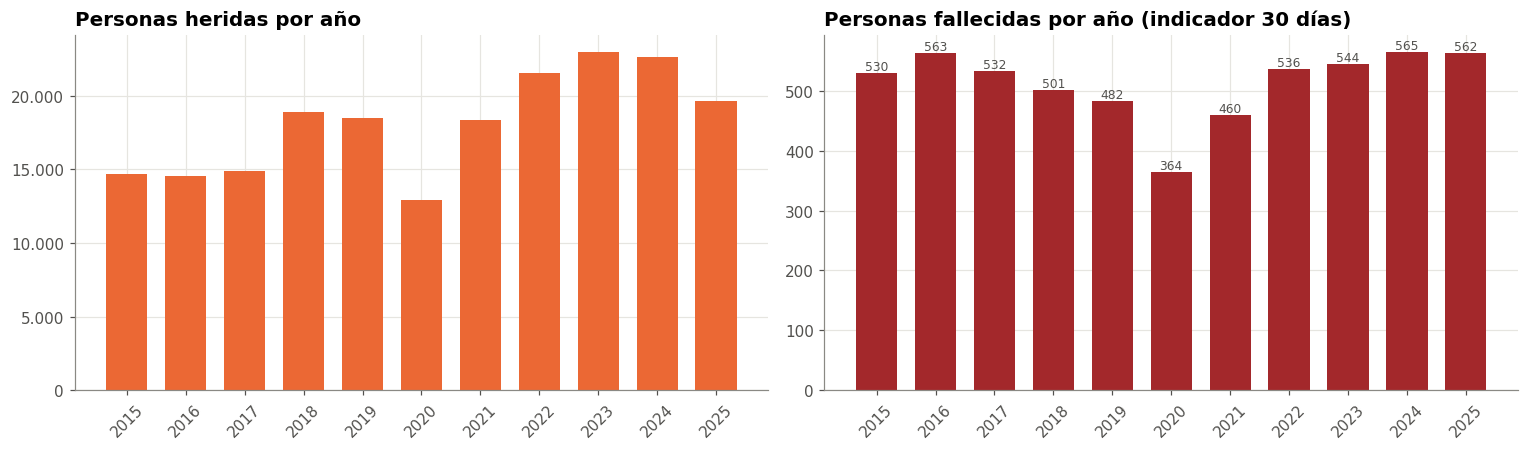

gravedad,HERIDO,MUERTO
anio,,
2015,14712,530
2016,14535,563
2017,14920,532
2018,18886,501
2019,18509,482
2020,12897,364
2021,18378,460
2022,21524,536
2023,22988,544


In [31]:
vict = act[act.gravedad.isin(['HERIDO', 'MUERTO'])]
va = vict.pivot_table(index='anio', columns='gravedad', values='id_actor', aggfunc='count')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(va.index, va.HERIDO, color=NARANJA, width=.7); axes[0].set_title('Personas heridas por año'); axes[0].yaxis.set_major_formatter(miles)
axes[1].bar(va.index, va.MUERTO, color='#a3282b', width=.7); axes[1].set_title('Personas fallecidas por año (indicador 30 días)')
for x, y in zip(va.index, va.MUERTO): axes[1].text(x, y + 5, int(y), ha='center', fontsize=8, color='#52514e')
for ax in axes: ax.set_xticks(va.index); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
va.astype(int)

### 6.2 ¿Quiénes mueren? Condición del actor vial

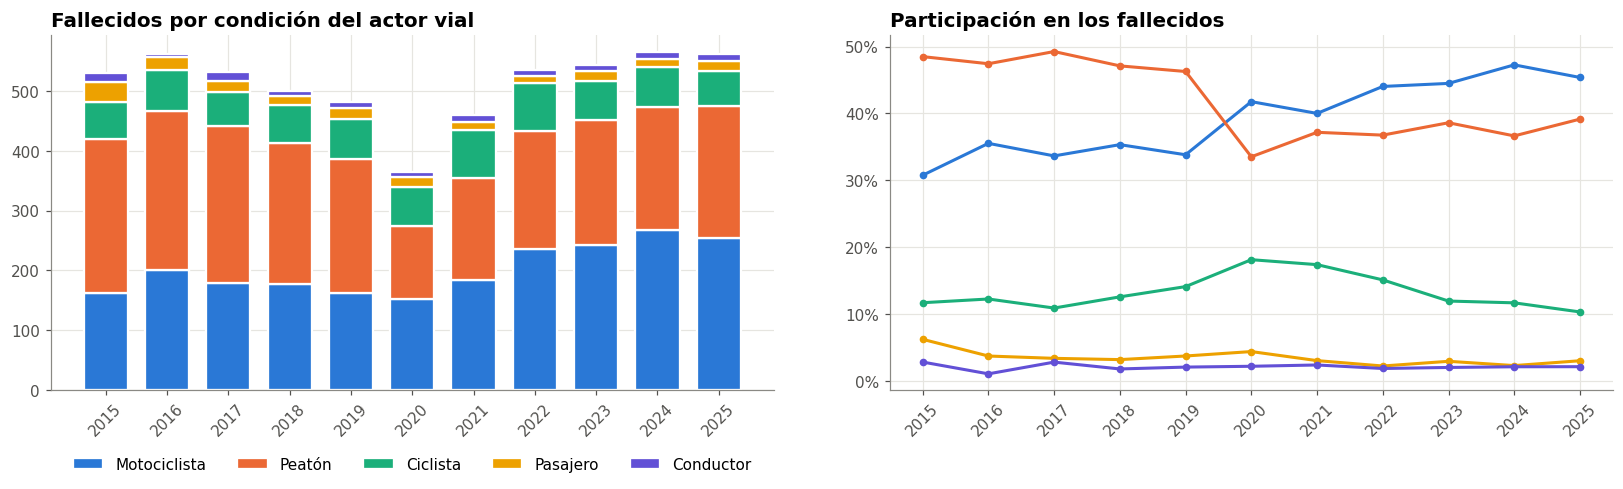

condicion,MOTOCICLISTA,PEATON,CICLISTA,PASAJERO,CONDUCTOR
anio,,,,,
2015,0.308,0.485,0.117,0.062,0.028
2016,0.355,0.474,0.123,0.037,0.011
2017,0.336,0.492,0.109,0.034,0.028
2018,0.353,0.471,0.126,0.032,0.018
2019,0.338,0.463,0.141,0.037,0.021
2020,0.418,0.335,0.181,0.044,0.022
2021,0.4,0.372,0.174,0.03,0.024
2022,0.44,0.368,0.151,0.022,0.019
2023,0.445,0.386,0.119,0.029,0.02


In [32]:
COND_COL = {'MOTOCICLISTA': AZUL, 'PEATON': NARANJA, 'CICLISTA': AQUA, 'PASAJERO': AMARILLO, 'CONDUCTOR': VIOLETA}
mu = act[act.gravedad == 'MUERTO'].pivot_table(index='anio', columns='condicion', values='id_actor', aggfunc='count').fillna(0)
mu = mu[[c for c in COND_COL if c in mu]]
share = mu.div(mu.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
abajo = np.zeros(len(mu))
for c in mu:
    axes[0].bar(mu.index, mu[c], bottom=abajo, color=COND_COL[c], label=c.title().replace('Peaton', 'Peatón'), width=.72, edgecolor='white', linewidth=1.5); abajo += mu[c].values
axes[0].set_title('Fallecidos por condición del actor vial'); axes[0].set_xticks(mu.index); axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(ncol=5, loc='upper center', bbox_to_anchor=(.5, -.15))
for c in share: axes[1].plot(share.index, share[c], color=COND_COL[c], lw=2, marker='o', ms=4, label=c.title())
axes[1].yaxis.set_major_formatter(pct); axes[1].set_title('Participación en los fallecidos'); axes[1].set_xticks(share.index); axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
share.round(3)

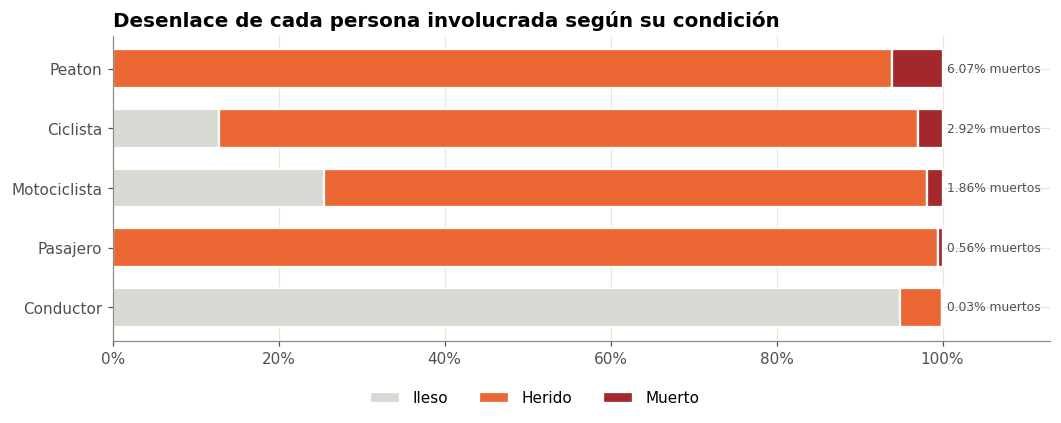

In [33]:
cg = act[act.condicion.notna() & act.gravedad.notna()]
tab = pd.crosstab(cg.condicion, cg.gravedad, normalize='index')[['ILESO', 'HERIDO', 'MUERTO']].sort_values('MUERTO')
fig, ax = plt.subplots(figsize=(11, 3.6))
izq = np.zeros(len(tab))
for g, c in [('ILESO', '#d9d8d2'), ('HERIDO', NARANJA), ('MUERTO', '#a3282b')]:
    ax.barh(tab.index.str.title(), tab[g], left=izq, color=c, label=g.title(), height=.65, edgecolor='white', linewidth=1.5); izq += tab[g].values
for i, v in enumerate(tab.MUERTO): ax.text(1.005, i, f'{v:.2%} muertos', va='center', fontsize=8, color='#52514e')
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1.13); ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(.45, -.12))
ax.set_title('Desenlace de cada persona involucrada según su condición'); plt.show()

### 6.3 Edad y sexo de las víctimas

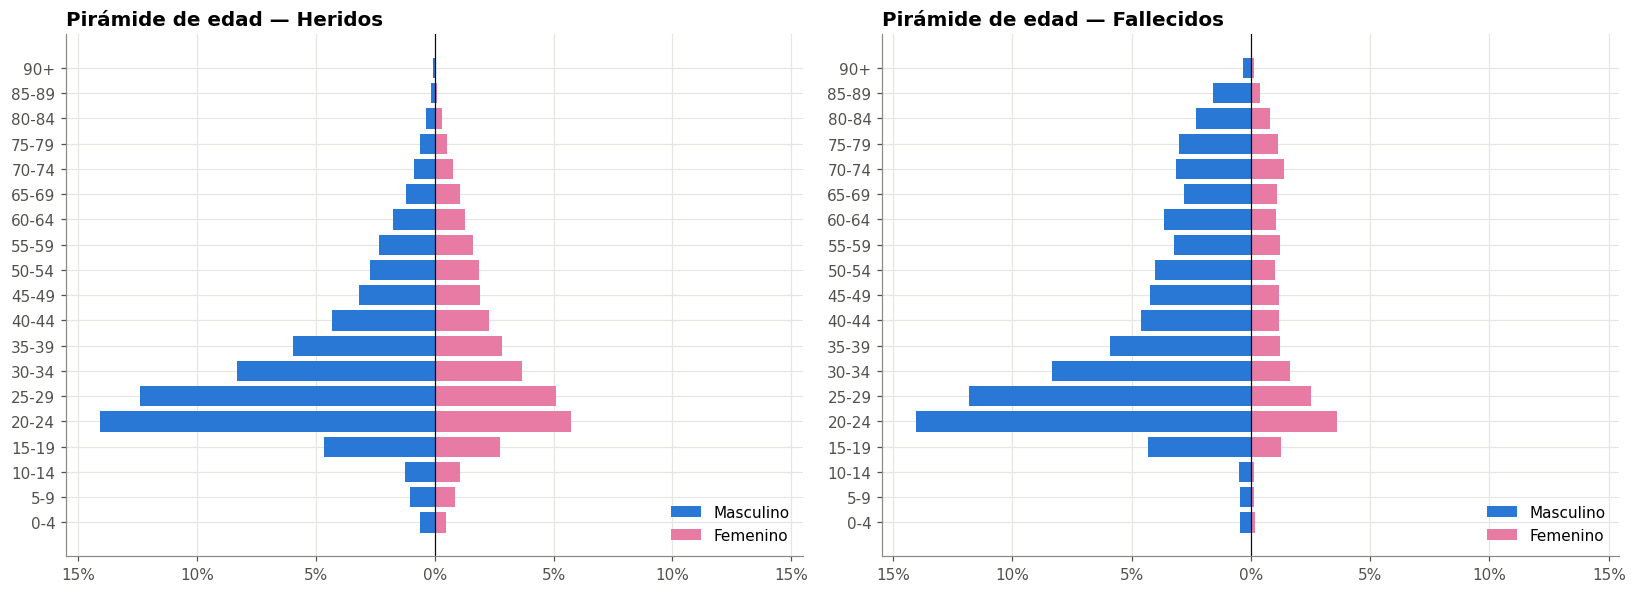

% hombres entre heridos: 65.8% | % hombres entre fallecidos: 78.7%
Edad mediana — heridos: 30.0 | fallecidos: 35.0


In [34]:
vv = vict.dropna(subset=['edad', 'sexo'])
vv = vv[vv.sexo.isin(['MASCULINO', 'FEMENINO'])]
bins = list(range(0, 95, 5)) + [120]
etq = [f'{b}-{b+4}' for b in bins[:-2]] + ['90+']
vv['grupo_edad'] = pd.cut(vv.edad, bins=bins, right=False, labels=etq)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, g, t in [(axes[0], 'HERIDO', 'Heridos'), (axes[1], 'MUERTO', 'Fallecidos')]:
    p = vv[vv.gravedad == g].pivot_table(index='grupo_edad', columns='sexo', values='id_actor', aggfunc='count', observed=False).fillna(0)
    p = p / p.values.sum()
    ax.barh(p.index.astype(str), -p['MASCULINO'], color=AZUL, label='Masculino', height=.8)
    ax.barh(p.index.astype(str), p['FEMENINO'], color=MAGENTA, label='Femenino', height=.8)
    lim = p.values.max() * 1.1; ax.set_xlim(-lim, lim)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{abs(x):.0%}'))
    ax.set_title(f'Pirámide de edad — {t}'); ax.legend(loc='lower right'); ax.axvline(0, color='#0b0b0b', lw=.8)
plt.tight_layout(); plt.show()
print('% hombres entre heridos:', f"{(vv[vv.gravedad=='HERIDO'].sexo=='MASCULINO').mean():.1%}",
      '| % hombres entre fallecidos:', f"{(vv[vv.gravedad=='MUERTO'].sexo=='MASCULINO').mean():.1%}")
print('Edad mediana — heridos:', vv[vv.gravedad=='HERIDO'].edad.median(), '| fallecidos:', vv[vv.gravedad=='MUERTO'].edad.median())

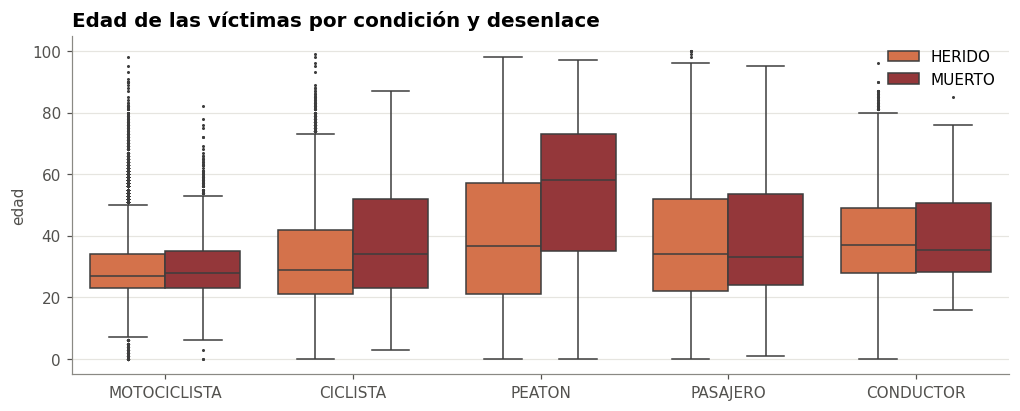

Edad mediana por condición y desenlace:
gravedad      HERIDO  MUERTO
condicion                   
CICLISTA        29.0    34.0
CONDUCTOR       37.0    35.5
MOTOCICLISTA    27.0    28.0
PASAJERO        34.0    33.0
PEATON          36.5    58.0
% de fallecidos con 60+ años: 22.8% | entre peatones fallecidos: 47.7%


In [35]:
fig, ax = plt.subplots(figsize=(11, 4))
orden = ['MOTOCICLISTA', 'CICLISTA', 'PEATON', 'PASAJERO', 'CONDUCTOR']
sns.boxplot(data=vict[vict.condicion.isin(orden)], x='condicion', y='edad', hue='gravedad', order=orden, hue_order=['HERIDO', 'MUERTO'],
            palette={'HERIDO': NARANJA, 'MUERTO': '#a3282b'}, fliersize=1, linewidth=1, ax=ax)
ax.set_title('Edad de las víctimas por condición y desenlace'); ax.set_xlabel(''); ax.legend(title='')
plt.show()
print('Edad mediana por condición y desenlace:')
print(vict[vict.condicion.isin(orden)].groupby(['condicion', 'gravedad']).edad.median().unstack())
m = vict[vict.gravedad == 'MUERTO']
print(f"% de fallecidos con 60+ años: {(m.edad >= 60).mean():.1%} | entre peatones fallecidos: {(m[m.condicion == 'PEATON'].edad >= 60).mean():.1%}")

### 6.4 Vehículos involucrados

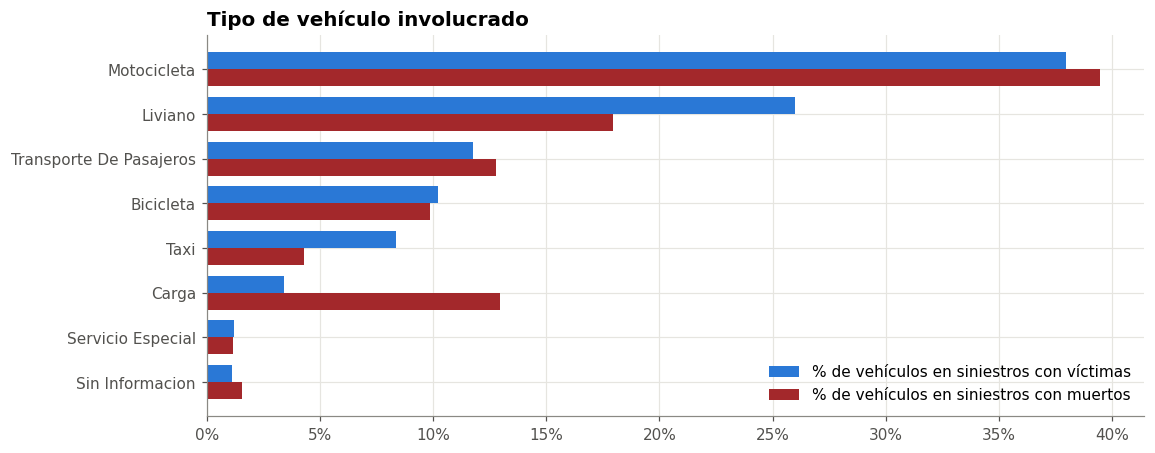

,vehiculos,en_siniestros_con_muertos,% vehículos,% en fatales
tipo_vehiculo,,,,
MOTOCICLETA,"82,652","3,312",37.9%,39.5%
LIVIANO,"56,657","1,507",26.0%,18.0%
TRANSPORTE DE PASAJEROS,"25,589","1,074",11.7%,12.8%
BICICLETA,"22,303",828,10.2%,9.9%
TAXI,"18,208",359,8.4%,4.3%
CARGA,"7,439","1,087",3.4%,12.9%
SERVICIO ESPECIAL,"2,592",97,1.2%,1.2%
SIN INFORMACION,"2,402",131,1.1%,1.6%


In [36]:
tv = veh[veh.tipo_vehiculo.notna() & veh.gravedad_siniestro.isin(['CON HERIDOS', 'CON MUERTOS'])]
t1 = tv.groupby('tipo_vehiculo').agg(vehiculos=('id_siniestro', 'count'),
                                     en_siniestros_con_muertos=('gravedad_siniestro', lambda s: (s == 'CON MUERTOS').sum()))
t1['% vehículos'] = t1.vehiculos / t1.vehiculos.sum(); t1['% en fatales'] = t1.en_siniestros_con_muertos / t1.en_siniestros_con_muertos.sum()
t1 = t1.sort_values('vehiculos')
fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(t1)); h = .38
ax.barh(y + h/2, t1['% vehículos'], h, color=AZUL, label='% de vehículos en siniestros con víctimas')
ax.barh(y - h/2, t1['% en fatales'], h, color='#a3282b', label='% de vehículos en siniestros con muertos')
ax.set_yticks(y, t1.index.str.title()); ax.xaxis.set_major_formatter(pct); ax.legend(loc='lower right')
ax.set_title('Tipo de vehículo involucrado'); plt.show()
t1.sort_values('vehiculos', ascending=False).style.format({'vehiculos': '{:,.0f}', 'en_siniestros_con_muertos': '{:,.0f}', '% vehículos': '{:.1%}', '% en fatales': '{:.1%}'})

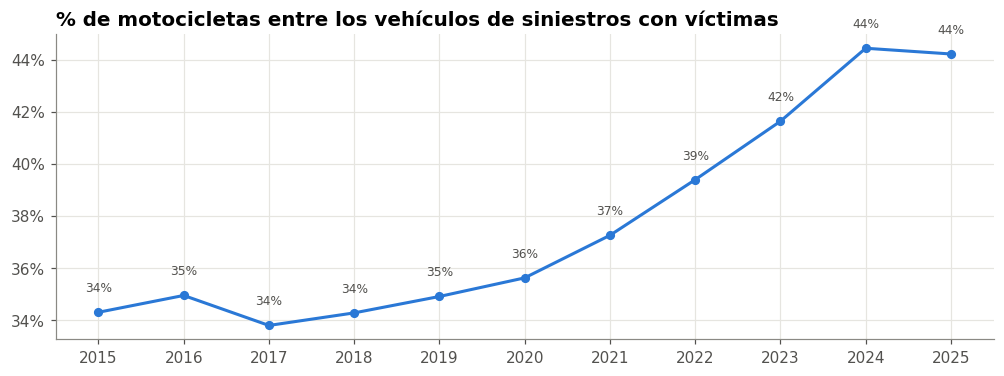

In [37]:
mot = veh[veh.gravedad_siniestro.isin(['CON HERIDOS', 'CON MUERTOS'])].copy()
mot['moto'] = mot.tipo_vehiculo == 'MOTOCICLETA'
sm = mot.groupby('anio').moto.mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(sm.index, sm.values, color=AZUL, lw=2, marker='o', ms=5)
for x, v in zip(sm.index, sm.values): ax.text(x, v + .008, f'{v:.0%}', ha='center', fontsize=8, color='#52514e')
ax.yaxis.set_major_formatter(pct); ax.set_xticks(sm.index); ax.set_title('% de motocicletas entre los vehículos de siniestros con víctimas')
plt.show()

## 7. Hallazgos de la exploración

**Estructura y calidad.** El archivo 2024 es la versión consolidada de la serie 2015–2024 con un esquema homogéneo, y los archivos 2019–2023 son versiones previas de los mismos registros (100 % de sus identificadores aparecen en él, salvo 2020 con 99,97 %, y los conteos difieren entre 6 y 14 siniestros por año). El resultado tiene 290.187 siniestros, 543.142 vehículos y 636.184 actores viales entre el 1 de enero de 2015 y el 31 de diciembre de 2025. Tres códigos de siniestro aparecen tanto en el archivo 2024 como en el 2025, cada uno con fecha de su propio año, y se conservan ambos; por eso la llave de la base es `(id_siniestro, anio)`, que es única, y con ella el 100 % de vehículos y actores queda enlazado a su siniestro. Los demás problemas encontrados son acotados: 386 edades superiores a 100 años, 5,2 % de siniestros sin coordenadas (hasta 11 % en 2015 y 0 % desde 2021), la variable `muerte_posterior` vacía en cerca de tres cuartas partes de los registros 2015–2020 y catorce banderas de factores asociados que no existen en 2025.

**Quiebre de registro.** Los siniestros con solo daños caen de más de 20.000 por año antes de 2020 a 1.115 en 2023, 1.037 en 2024 y ninguno en 2025, mientras los siniestros con heridos (entre 10.403 y 12.586 por año, salvo 8.580 en 2020) y con muertos (entre 356 y 551) se mantienen estables. La caída del total de siniestros que se ve en la serie es, por tanto, un efecto del registro y no de la seguridad vial, y el universo comparable es el de 130.021 siniestros con víctimas.

**Tiempo.** El mes con menos siniestros con víctimas fue abril de 2020 (332), durante las cuarentenas por COVID-19, y el de más fue marzo de 2019 (1.243). La media móvil anual se recuperó a niveles cercanos a los de 2019 hacia 2022 y se mantuvo así hasta 2024; en 2025 hubo 11.573 siniestros con víctimas frente a 12.912 en 2024. El volumen tiene su pico a las 7 a. m. y en los días laborales, pero la letalidad se comporta al revés: es máxima en la madrugada (10,1 % a las 2 a. m.) y el domingo (5,02 %, frente a 3,86 % el martes). Las personas fallecidas por año oscilan entre 364 (2020) y 565 (2024), con 562 en 2025, y los heridos suben de 14.712 en 2015 a 22.988 en 2023.

**Espacio.** Kennedy concentra el 13,9 % de los siniestros con víctimas y, junto con Engativá, Suba, Puente Aranda y Bosa, reúne el 46 %. En letalidad destacan Usme (6,11 %), Ciudad Bolívar (5,87 %) y Fontibón (4,90 %), por encima del promedio de 4,22 %, mientras Chapinero tiene la más baja (2,92 %); Sumapaz registra solo 13 casos y su tasa no es comparable. El mapa de puntos muestra que los siniestros con muertos se alinean sobre los grandes corredores viales, lo que sugiere que el análisis espacial debe hacerse a nivel de vía o tramo y no solo de localidad.

**Tipo de siniestro y factores asociados.** Los choques son el 63,9 % de los siniestros con víctimas pero el 48,6 % de los fatales; los atropellos pasan del 25,7 % al 42,2 % y los volcamientos tienen la letalidad más alta (10,57 %). Entre las banderas, el exceso de velocidad multiplica por 5,38 la letalidad (20,94 % frente a 3,89 %), la presencia de vehículos de carga por 4,07, la embriaguez por 2,25, la presencia de peatón por 2,07 y la de persona mayor por 1,55. La bandera de motocicleta, presente en el 56,6 % de los siniestros con víctimas, no cambia la letalidad del siniestro (riesgo relativo 1,00). Las banderas `CON_TPI` y `CON_TAXI` tienen prevalencia y letalidad prácticamente idénticas, por lo que parecen describir el mismo hecho y no deberían usarse juntas en un modelo.

**Personas y vehículos.** La participación de los motociclistas en los fallecidos sube de 30,8 % en 2015 a 47,3 % en 2024 (45,4 % en 2025), y la de los peatones baja de 48,5 % a 36,6 % (39,1 % en 2025); en paralelo, las motocicletas pasan del 34 % al 44 % de los vehículos involucrados en siniestros con víctimas. Los hombres son el 65,8 % de los heridos y el 78,7 % de los fallecidos, con edades medianas de 30 y 35 años respectivamente; el contraste más marcado está en los peatones, cuya edad mediana al fallecer es 58 años frente a 36,5 entre los heridos. Los vehículos de carga son el 3,4 % de los vehículos en siniestros con víctimas pero aparecen en el 12,9 % de los vehículos de siniestros con muertos. Conviene tener presente que peatones y pasajeros casi solo se registran cuando resultan lesionados, de modo que su proporción de ilesos no es comparable con la de los conductores.

**Implicaciones para el modelamiento.** Ninguna variable aislada explica bien la letalidad: la asociación más alta con el siniestro fatal es la del elemento de choque (V de Cramér 0,137), seguida de carga (0,125), velocidad (0,108) y clase de siniestro (0,106), todas débiles. Esto, junto con el desbalance de la variable objetivo (4,22 % de siniestros fatales), indica que un modelo de clasificación de gravedad necesitará combinar variables temporales, espaciales, de tipo de siniestro y de actores, con técnicas para clases desbalanceadas, y entrenarse sobre 2015–2024 si se quieren usar todas las banderas, dejando 2025 como periodo de validación solo con las variables disponibles en ese año.